# Drug resistance mutations → peptide QSAR

Point mutations that make a cancer target resistant to a drug are turned into
short peptide sequences, converted to 3D structures, and used to train
SSPR classification models. The notebook covers everything either side of
MultiPASS itself, which runs separately on Windows.

| Section | |
| --- | --- |
| 1–2 | Setup, reference data |
| 3 | Cut mutations into peptide windows |
| 4–6 | Pick targets worth modelling, drop duplicate mutations |
| 7 | Write SDF structures — **hand off to MultiPASS here** |
| 8–9 | Read model performance back, summarise |

See `README.md` for how to obtain `data/` and how the external toolchain fits in.

## 1. Setup

Resolves the repository root, then `data/` and `results/` under it (override
with `AAS_DATA_DIR` / `AAS_RESULTS_DIR`) and changes into the data directory,
since the cells below address files relatively — `fasta/`, `csv/` and so on.

In [1]:
"""Project setup: imports and paths.

The dataset is NOT stored in this repository. Put it at <repo>/data, or point
AAS_DATA_DIR at it. All figures and derived files are written to <repo>/results
(or AAS_RESULTS_DIR).
"""
import os
from pathlib import Path

import numpy as np
import pandas as pd
from Bio import SeqIO


def _repo_root(start=None):
    start = (Path(start) if start else Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "requirements.txt").exists() or (candidate / ".git").exists():
            return candidate
    return start


REPO_ROOT = _repo_root()
DATA_DIR = Path(os.environ.get("AAS_DATA_DIR", REPO_ROOT / "data")).resolve()
RESULTS_DIR = Path(os.environ.get("AAS_RESULTS_DIR", REPO_ROOT / "results")).resolve()
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

if not (DATA_DIR / "fasta").is_dir():
    raise FileNotFoundError(
        f"No data found under {DATA_DIR}. See README.md -> 'Getting the data'."
    )

# Cells below use paths relative to the data root ('fasta/', 'csv/', ...).
os.chdir(DATA_DIR)
print("data   :", DATA_DIR)
print("results:", RESULTS_DIR)


data   : /Users/annaantipova/Desktop/lagushka/data
results: /Users/annaantipova/Desktop/lagushka/results


## 2. Reference data and helpers

`drugs` lists every therapy that appears as a resistance annotation — it
doubles as the column layout of the per-target tables and as the label
vocabulary in the SDF files.

`parse_fasta_file` reads a FASTA into `{id: sequence}`. `extract_substring`
applies one AA mutation to the wild-type sequence and returns a window of the
requested length centred on it, or an empty string when the window would run
past either end of the protein.

In [2]:
drugs = ['Imatinib', 'Tyrosine kinase inhibitor - NS', 'Gefitinib', 'Erlotinib', 'Crizotinib', 'Endocrine therapy', 'Dasatinib', 'Purine', 'Purine Analogue',
         'Ibrutinib', 'Afatinib', 'Osimertinib', 'Vismodegib', 'Vemurafenib', 'Ceritinib', 'Alectinib', 'Dabrafenib', 'Quizartinib', 'Nilotinib',
         'Lorlatinib', 'Sorafenib', 'BGJ398', 'Pemigatinib', 'Bosutinib', 'Brigatinib', 'Sunitinib', 'PD0325901', 'Pembrolizumab', 'Capmatinib',
         'Selumetinib', 'PF-04217903', 'Savolitinib', 'Ivosidenib']

def parse_fasta_file(input_file):
    """Return a dict of {id:gene_seq} pairs based on the sequences in the input FASTA file
    input_file -- a file handle for an input fasta file
    """
    parsed_seqs = {}
    curr_seq_id = None
    curr_seq = []

    for line in input_file:
        line = line.strip()
        if line.startswith(">"):
            if curr_seq_id is not None:
                parsed_seqs[curr_seq_id] = ''.join(curr_seq)
            curr_seq_id = line[1:]
            curr_seq = []
            continue
        curr_seq.append(line)
    parsed_seqs[curr_seq_id] = ''.join(curr_seq)
    return parsed_seqs

def extract_substring(peptide, mutation_data, length):
    parts = mutation_data.split('.')
    mutation_position_str = ''.join(filter(str.isdigit, parts[1]))
    mutation_position = int(mutation_position_str) - 1
    if (mutation_position >= len(peptide)):
      return ''
    start_pos = mutation_position - (length // 2)
    end_pos = start_pos + length
    peptide = list(peptide)
    peptide[mutation_position] = parts[1][-1]
    final = peptide[start_pos:end_pos]
    if (len(final) == length):
      return final
    else:
      return ''

In [3]:
path = 'fasta/'
files = sorted(
    os.path.splitext(filename)[0]
    for filename in os.listdir(path)
    if filename.endswith('.faa')
)


## 3. Build peptide datasets

For every target: load the COSMIC export, keep missense substitutions, flag
each mutation with the drug it confers resistance to, then cut a peptide window
of every odd length from 3 to 37 centred on the mutated residue.

Result: `<TARGET>_prepared.csv`, one row per mutation and peptide length.

> Runs for about 20 minutes over all 29 targets. The output is already in
> `data/prepared_data/`, so skip ahead unless the inputs changed.

In [4]:
peptide_length = list(range(3, 38, 2))
for_plot = pd.DataFrame(columns=['gene','bad','good'])

for name in files:
  print(name)
  good = 0
  bad = 0
  gene = pd.read_csv("csv/{}.csv".format(name))
  f = open('fasta/{}.faa'.format(name))
  parsed_seqs = parse_fasta_file(f)
  mutations = pd.read_csv("mutations/{}_mutations.csv".format(name))
  for col in drugs:
      gene[col] = 0
  gene = gene.loc[gene['Type'] == 'Substitution - Missense']
  gene['Peptide'] = '0'
  gene = gene.dropna(subset=["Position"])
  for idx, mutation in mutations['AA Mutation'].items():
    if mutation in gene['AA Mutation'].values:
      res_drug = str(mutations['Drug'][idx])
      index = gene.index[gene['AA Mutation']==mutation].tolist()
      print(index)
      print(res_drug)
      for ind in index:
        bad = bad + 1
        gene.at[ind,res_drug] = 1
  data = gene.copy(deep=True)
  peptide = next(iter(parsed_seqs.values()))
  for index, row in data.iterrows():
    mutation_data = row['AA Mutation']
    for peptide_l in peptide_length:
        new_row = row.copy(deep=True)
        new_row['Peptide'] = ''.join(extract_substring(peptide, mutation_data, peptide_l))
        gene = pd.concat([gene, pd.DataFrame([new_row])], ignore_index=True)
  gene['length'] = gene['Peptide'].apply(lambda x: len(x))
  gene = gene.drop(gene[gene['length'] < 3].index)
  good = gene['AA Mutation'].nunique()
  new_row = {'gene': name, 'bad': bad, 'good': good}
  for_plot = pd.concat([for_plot, pd.DataFrame([new_row])], ignore_index=True)
  gene.to_csv('prepared_data/{}_prepared.csv'.format(name))

ABL1
[243]
Imatinib
[243]
Imatinib
[243]
Imatinib
[148]
Imatinib
[148]
Imatinib
[142]
Tyrosine kinase inhibitor - NS
[153]
Tyrosine kinase inhibitor - NS
[161]
Tyrosine kinase inhibitor - NS
[161]
Tyrosine kinase inhibitor - NS
[192]
Tyrosine kinase inhibitor - NS
[243]
Tyrosine kinase inhibitor - NS
[153]
Tyrosine kinase inhibitor - NS
[244, 247, 248]
Tyrosine kinase inhibitor - NS
[290]
Tyrosine kinase inhibitor - NS
[290]
Tyrosine kinase inhibitor - NS
[320]
Tyrosine kinase inhibitor - NS
[322]
Tyrosine kinase inhibitor - NS
[244, 247, 248]
Imatinib
[244, 247, 248]
Imatinib
[244, 247, 248]
Imatinib
[243]
Imatinib
[245]
Imatinib
[153]
Imatinib
[162]
Imatinib
[153]
Imatinib
[148]
Imatinib
[158, 159]
Imatinib
[142]
Imatinib
[320]
Imatinib
[290]
Imatinib
[290]
Imatinib
[290]
Imatinib
[161]
Imatinib
[161]
Imatinib
[161]
Imatinib
[243]
Imatinib
[243]
Imatinib
[243]
Imatinib
[243]
Imatinib
[243]
Imatinib
[243]
Imatinib
[243]
Imatinib
[243]
Imatinib
[281]
Imatinib
[243]
Tyrosine kinase inhi

## 4. Mutation statistics per target

How many distinct resistance mutations each target actually has, and how they
split across drugs. This is what decides which targets are worth modelling.

In [6]:
import os
import pandas as pd

# Define the path to the directory containing the files
path = 'prepared_data/'

# Initialize a dictionary to store the counts for each file
unique_counts = {}

# Iterate over each file in the directory
for filename in os.listdir(path):
    if filename.endswith('prepared.csv'):  # Adjust the file extension if necessary
        file_path = os.path.join(path, filename)
        # Read the file into a DataFrame
        df = pd.read_csv(file_path)
        # Check if the 'AA mutation' column exists in the DataFrame
        if 'AA Mutation' in df.columns:
            # Count the number of unique values in the 'AA mutation' column
            unique_count = df['AA Mutation'].nunique()
            # Store the result in the dictionary
            unique_counts[filename] = unique_count
        else:
            print(f"Column 'AA mutation' not found in {filename}")

# Convert the dictionary to a DataFrame for better visualization
result_df = pd.DataFrame(list(unique_counts.items()), columns=['Filename', 'Unique AA Mutations'])

# Display the results
print(result_df)


                              Filename  Unique AA Mutations
0                    FLT3_prepared.csv                  840
1                  MAP2K1_prepared.csv                  197
2                     SMO_prepared.csv                  491
3    EGFR_ENST00000454757_prepared.csv                 1083
4                    EGFR_prepared.csv                 1236
5   NT5C2_ENST00000470299_prepared.csv                   12
6                    ESR1_prepared.csv                  423
7   NT5C2_ENST00000404739_prepared.csv                  147
8    IDH1_ENST00000415913_prepared.csv                  243
9                    JAK1_prepared.csv                  595
10    MET_ENST00000397752_prepared.csv                  847
11                    KIT_prepared.csv                  977
12  FGFR2_ENST00000346997_prepared.csv                  552
13   BRAF_ENST00000288602_prepared.csv                  601
14   IDH1_ENST00000345146_prepared.csv                  232
15    ALK_ENST00000618119_prepared.csv  

In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

path = 'prepared_data/'
files = [os.path.splitext(filename)[0] for filename in os.listdir(path) if filename.endswith('_prepared.csv')]
non_zero_counts = {}

drug_colors = {}
drug_palette = list(mcolors.TABLEAU_COLORS.values())  # only 10 colours; cell 7 swaps in a wider palette
drug_to_color = {drug: color for drug, color in zip(drugs, drug_palette)}
mutation_counts = {name: {drug: 0 for drug in drugs} for name in files}

for name in files:
    gene = pd.read_csv(f'{path}{name}.csv')
    # A residue change can be recorded either as a clean single-nucleotide
    # substitution (c.123A>G) or as an insertion-deletion / unknown CDS
    # (delins, c.?). Where both spellings exist for the same AA mutation,
    # keep the clean one and drop the ambiguous duplicates.
    mask_c_question = gene['CDS Mutation'].str.contains(r'delins|c\.\?', na=False)
    mask_c_xy = gene['CDS Mutation'].str.contains(r'c\.\d+[A-Za-z]>[A-Za-z]', na=False)
    for aa_mutation in gene['AA Mutation'].unique():
        subset = gene[gene['AA Mutation'] == aa_mutation]
        has_valid_mutation = subset['CDS Mutation'].str.contains(r'c\.\d+[A-Za-z]>[A-Za-z]', na=False).any()
        if has_valid_mutation:
            mask_subset_c_question = subset['CDS Mutation'].str.contains(r'delins|c\.\?', na=False)
            gene = gene[~((gene['AA Mutation'] == aa_mutation) & mask_subset_c_question)]
    # One row per mutation, one column per drug; a non-zero entry means at
    # least one peptide of that mutation is annotated resistant to that drug.
    sum_per_mutation = gene.groupby('AA Mutation')[drugs].sum()
    filtered_columns = sum_per_mutation.loc[:, (sum_per_mutation.sum() > 0)]
    filtered_rows = filtered_columns[(filtered_columns > 0).any(axis=1)]
    print(filtered_rows)
    total_non_zero_count = len(filtered_rows)

    for drug in drugs:
      if drug in filtered_rows.columns:
        mutation_counts[name][drug] = (filtered_rows[drug] != 0).sum()
      else:
        mutation_counts[name][drug] = 0

             Quizartinib  Sorafenib  Sunitinib
AA Mutation                                   
p.D835F               18          0          0
p.D835H                0         18          0
p.D835I               18          0          0
p.D835V               18          0          0
p.D835X                0         18          0
p.D835Y               18         18         18
p.F691L               18         18          0
             PD0325901  Selumetinib
AA Mutation                        
p.F129L             18            0
p.L115P             18            0
p.P124L              0           18
             Vismodegib
AA Mutation            
p.A459V              18
p.C469Y              18
p.D473G              18
p.D473H              18
p.D473N              18
p.D473Y              18
p.F460L              18
p.G497W              18
p.H231R              18
p.Q477E              18
p.S533N              18
p.T241M              18
p.V321A              18
p.V321M              18
p.W281C      

In [8]:
mutation_counts

{'FLT3_prepared': {'Imatinib': 0,
  'Tyrosine kinase inhibitor - NS': 0,
  'Gefitinib': 0,
  'Erlotinib': 0,
  'Crizotinib': 0,
  'Endocrine therapy': 0,
  'Dasatinib': 0,
  'Purine': 0,
  'Purine Analogue': 0,
  'Ibrutinib': 0,
  'Afatinib': 0,
  'Osimertinib': 0,
  'Vismodegib': 0,
  'Vemurafenib': 0,
  'Ceritinib': 0,
  'Alectinib': 0,
  'Dabrafenib': 0,
  'Quizartinib': np.int64(5),
  'Nilotinib': 0,
  'Lorlatinib': 0,
  'Sorafenib': np.int64(4),
  'BGJ398': 0,
  'Pemigatinib': 0,
  'Bosutinib': 0,
  'Brigatinib': 0,
  'Sunitinib': np.int64(1),
  'PD0325901': 0,
  'Pembrolizumab': 0,
  'Capmatinib': 0,
  'Selumetinib': 0,
  'PF-04217903': 0,
  'Savolitinib': 0,
  'Ivosidenib': 0},
 'MAP2K1_prepared': {'Imatinib': 0,
  'Tyrosine kinase inhibitor - NS': 0,
  'Gefitinib': 0,
  'Erlotinib': 0,
  'Crizotinib': 0,
  'Endocrine therapy': 0,
  'Dasatinib': 0,
  'Purine': 0,
  'Purine Analogue': 0,
  'Ibrutinib': 0,
  'Afatinib': 0,
  'Osimertinib': 0,
  'Vismodegib': 0,
  'Vemurafenib': 0,

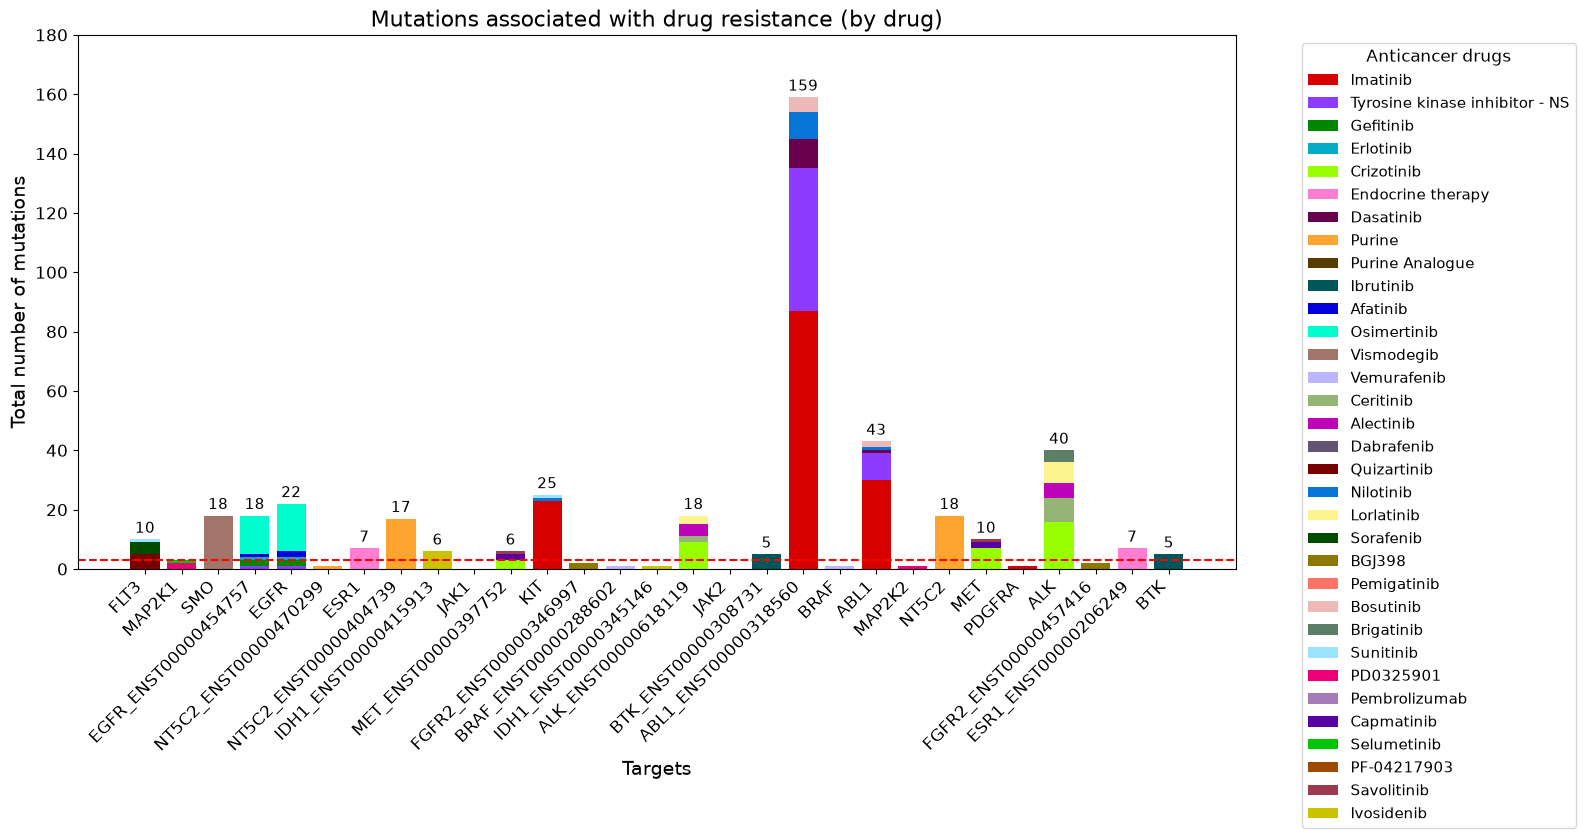

In [9]:
import colorcet as cc
gene_names = [os.path.splitext(f)[0].replace('_prepared', '') for f in files]
palette = cc.glasbey[:40]
drug_to_color = {drug: palette[i % len(palette)] for i, drug in enumerate(drugs)}
plt.figure(figsize=(16, 8))
bottom = [0] * len(files)
x_labels = list(mutation_counts.keys())

for i, drug in enumerate(drugs):
    drug_values = [mutation_counts[name][drug] for name in x_labels]
    plt.bar(gene_names, drug_values, bottom=bottom, color=drug_to_color[drug], label=drug)
    bottom = [bottom[j] + drug_values[j] for j in range(len(files))]

plt.xlabel('Targets', fontsize=14)
plt.ylabel('Total number of mutations', fontsize=14)
plt.title('Mutations associated with drug resistance (by drug)', fontsize=16)
plt.axhline(y=3, color='red', linestyle='--', linewidth=1.5)

plt.legend(
    title="Anticancer drugs",
    fontsize=11,
    title_fontsize=12,
    ncol=1,
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(fontsize=12)
plt.ylim(top=180)

for i, gene in enumerate(gene_names):
    total = bottom[i]
    if total > 3:
        plt.text(
            i, 
            total + 1,
            str(total),
            ha='center',
            va='bottom',
            fontsize=11
        )
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/mutation_counts_plot.png', dpi=300, bbox_inches='tight')
plt.show()

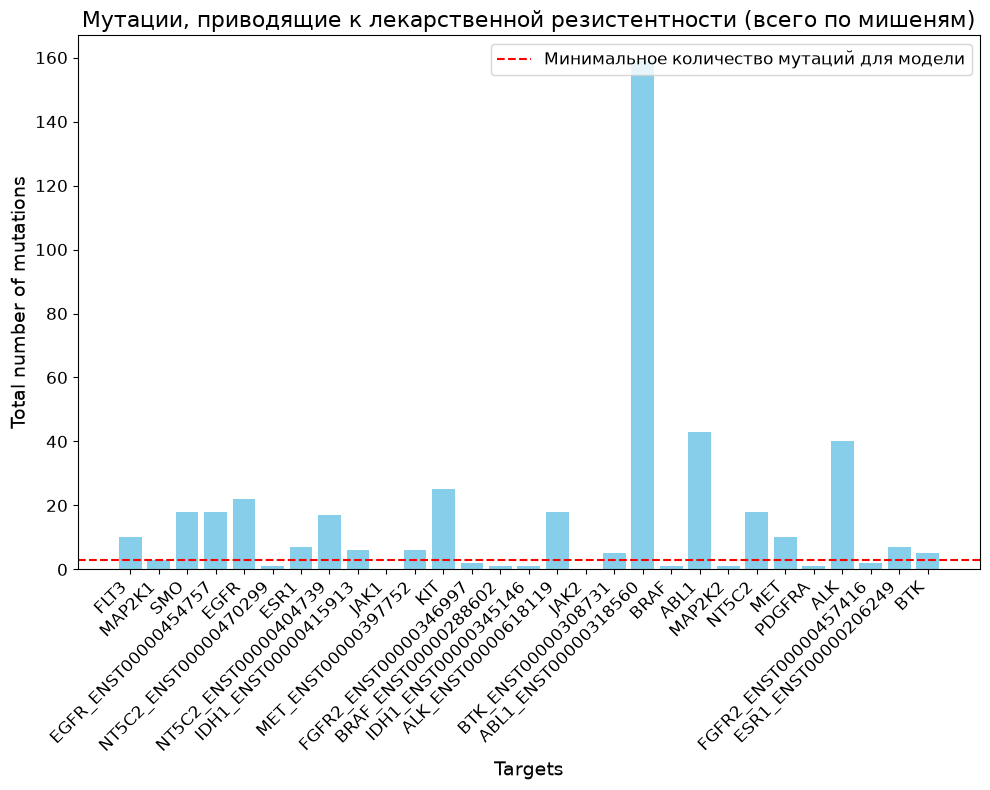

In [10]:
import matplotlib.pyplot as plt

total_mutations = [sum(mutation_counts[name].values()) for name in x_labels]
plt.figure(figsize=(10, 8))
plt.bar(gene_names, total_mutations, color='skyblue')
plt.axhline(y=3, color='red', linestyle='--', linewidth=1.5, label='Minimum number of mutations required to build a model')
plt.xlabel('Targets', fontsize=14)
plt.ylabel('Total number of mutations', fontsize=14)
plt.title('Drug resistance-associated mutations (total per target)', fontsize=16)
plt.legend(loc='upper right', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/mutation_counts_total_plot.png', dpi=300, bbox_inches='tight')
plt.show()


## 5. Targets selected for modelling

Targets with at least three resistance-associated mutations — the red line in
the plots above. Below that, MultiPASS has too few positives to train on. Eighteen
of the twenty-nine targets qualify.

In [11]:
filenames_above_threshold = ['FLT3', 'KIT', 'SMO', 'ABL1', 'ABL1_ENST00000318560',
                             'ALK' ,'BTK_ENST00000308731', 'BTK', 'EGFR', 'EGFR_ENST00000454757', 'ESR1_ENST00000206249',
                             'ESR1', 'IDH1_ENST00000415913', 'MET_ENST00000397752', 'NT5C2_ENST00000404739', 'MET', 'NT5C2', 'ALK_ENST00000618119']

## 6. Collapse duplicate mutations

The same AA mutation appears once per COSMIC sample, so a mutation seen in
three samples carries three identical sets of 18 peptides. Keeping them would
weight frequent mutations by how often they were sequenced rather than by
anything biological, so `head(18)` — one row per peptide length — keeps a
single complete set.

Written as `<TARGET>_filtered.csv`, and only for the targets selected above.

In [12]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

path = 'prepared_data/'
files = [os.path.splitext(filename)[0].replace('_prepared', '') for filename in os.listdir(path)]
non_zero_counts = {}
for name in filenames_above_threshold:
    gene = pd.read_csv(f'{path}{name}_prepared.csv')
    gene = gene.groupby('AA Mutation').head(18)
    print(name)
    gene.to_csv(f'{path}{name}_filtered.csv', index=False)

FLT3
KIT
SMO
ABL1
ABL1_ENST00000318560
ALK
BTK_ENST00000308731
BTK
EGFR
EGFR_ENST00000454757
ESR1_ENST00000206249
ESR1
IDH1_ENST00000415913
MET_ENST00000397752
NT5C2_ENST00000404739
MET
NT5C2
ALK_ENST00000618119


## 7. Peptide structures (SDF)

Each peptide sequence becomes an RDKit molecule carrying three properties —
the AA mutation, the peptide itself, and the drug it confers resistance to
(`Not resistant` when none). One SDF per target and peptide length; these files
are the input to the MultiPASS software.

`chargePeptide` assigns formal charges at physiological pH — negative on Asp
and Glu carboxyls, positive on the Lys amine, the His imidazole, the Arg
guanidine and the N-terminus. It is defined here but left commented out at the
call site: both charged and uncharged variants were run, and the uncharged ones
are what the SDF cell writes.

In [13]:
# pyPept is installed from requirements.txt:
#   pip install "pypept @ git+https://github.com/Boehringer-Ingelheim/pyPept.git"
# The CLI below needs a source checkout; set PYPEPT_DIR to point at it.
PYPEPT_DIR = Path(os.environ.get("PYPEPT_DIR", REPO_ROOT / "external" / "pyPept"))


In [17]:
def chargePeptide(mol):
    carboxyl = Chem.MolFromSmarts('C(=O)O')# aspartate and glutamate
    lysine = Chem.MolFromSmarts('C(CCN)C[C@@H](C(=O))')
    imydazoline = Chem.MolFromSmarts('c1cnc[nH]1') # histidine
    guanidine = Chem.MolFromSmarts('NC(N)=N') # arginine
    mol.GetAtomWithIdx(0).SetFormalCharge(1) # charge N end of peptide

    carboxyl_groups_pos = list(mol.GetSubstructMatches(carboxyl))

    if len(carboxyl_groups_pos) != 0:
        for g in carboxyl_groups_pos:
            atoms_pos = list(g)
            mol.GetAtomWithIdx(atoms_pos[2]).SetFormalCharge(-1)

    lysine_groups_pos = list(mol.GetSubstructMatches(lysine))

    if len(lysine_groups_pos) != 0:
        for g in lysine_groups_pos:
            atoms_pos = list(g)
            mol.GetAtomWithIdx(atoms_pos[3]).SetFormalCharge(1)

    imydazoline_groups_pos = list(mol.GetSubstructMatches(imydazoline))

    if len(imydazoline_groups_pos) != 0:
        for g in imydazoline_groups_pos:
            atoms_pos = list(g)
            mol.GetAtomWithIdx(atoms_pos[4]).SetFormalCharge(1)

    guanidine_groups_pos = list(mol.GetSubstructMatches(guanidine))

    if len(guanidine_groups_pos) != 0:
        for g in guanidine_groups_pos:
            atoms_pos = list(g)
            mol.GetAtomWithIdx(atoms_pos[3]).SetFormalCharge(1)


In [18]:
path = 'prepared_data/'
files = sorted(
    os.path.splitext(filename)[0]
    for filename in os.listdir(path)
    if filename.endswith('.csv')
)

In [21]:
from rdkit import Chem
from rdkit.Chem import Draw

drugs = ['Imatinib', 'Tyrosine kinase inhibitor - NS', 'Gefitinib', 'Erlotinib', 'Crizotinib', 'Endocrine therapy', 'Dasatinib', 'Purine', 'Purine Analogue',
         'Ibrutinib', 'Afatinib', 'Osimertinib', 'Vismodegib', 'Vemurafenib', 'Ceritinib', 'Alectinib', 'Dabrafenib', 'Quizartinib', 'Nilotinib',
         'Lorlatinib', 'Sorafenib', 'BGJ398', 'Pemigatinib', 'Bosutinib', 'Brigatinib', 'Sunitinib', 'PD0325901', 'Pembrolizumab', 'Capmatinib',
         'Selumetinib', 'PF-04217903', 'Savolitinib', 'Ivosidenib']

for gene_file in filenames_above_threshold:
    gene = pd.read_csv("prepared_data/{}_filtered.csv".format(gene_file))
    for length, group in gene.groupby(['length']):
        output_path = f"sdf/uncharged/{gene_file}_{int(length[0])}.sdf"
        writer = Chem.SDWriter(output_path)

        for index, row in group.iterrows():
            non_zero_columns = row.index[row != 0].tolist()
            common_items = set(non_zero_columns) & set(drugs)
            # Format "Drug" field as required
            drugs_resistant = '\n'.join(common_items) if common_items else 'Not resistant'
            # Generate RDKit molecule from peptide sequence
            molecule = Chem.MolFromSequence(row['Peptide'])
            try:
                #chargePeptide(molecule)  # Uncomment if needed
                if molecule:
                  molecule.SetProp("Mutation", str(row['AA Mutation']))
                  molecule.SetProp("Peptide", str(row['Peptide']))
                  molecule.SetProp("Drug", drugs_resistant)
                  writer.write(molecule)
            except:
                continue
        writer.close()
        print(f"SDF file created for {gene_file} with peptide length {int(length[0])}")


SDF file created for FLT3 with peptide length 3
SDF file created for FLT3 with peptide length 5


KeyboardInterrupt: 

## 8. Parsing MultiPASS run logs

Everything above happens before MultiPASS; this section reads its output back.

`data/multipass/merged.txt` concatenates the `ConsolidatedOutput*.txt` logs
produced by `scripts/multipass/run_mna_models.ps1`. Each block records which
SDF was loaded, at which MNA descriptor level, and the resulting `Average IAP`
— the value used here as AUC. The regexes below pull out
target / peptide length / MNA level / IAP and reshape them for plotting.

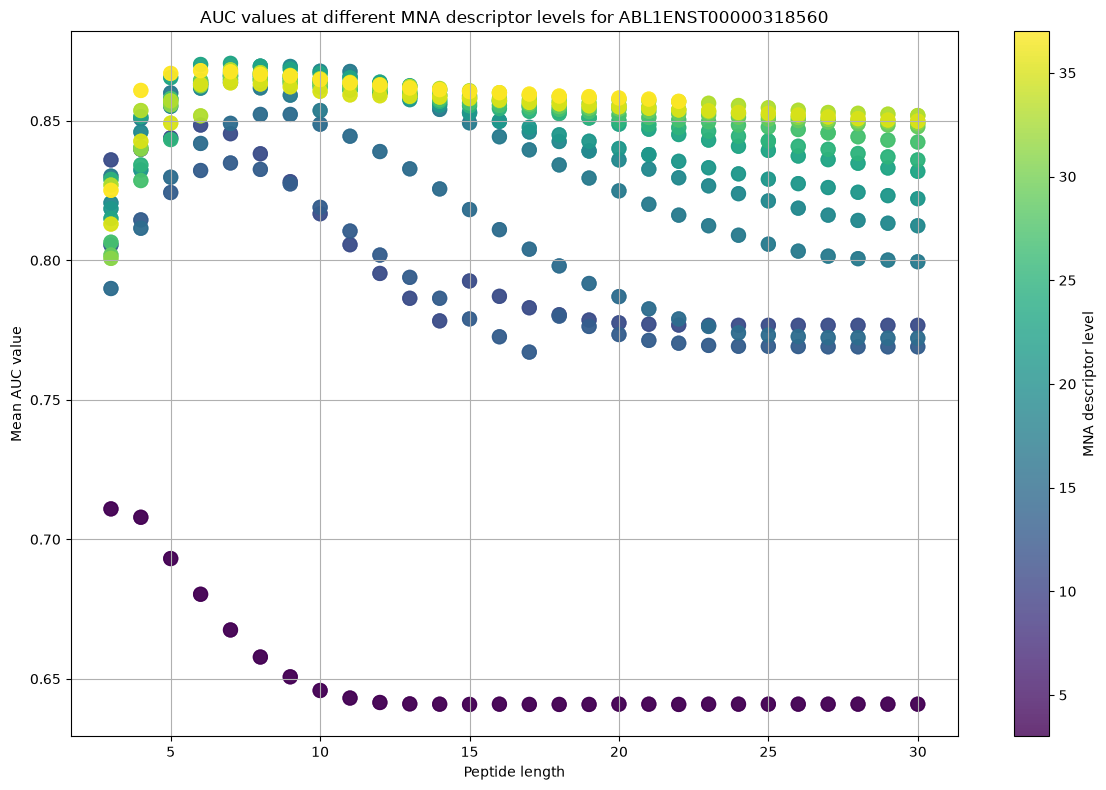

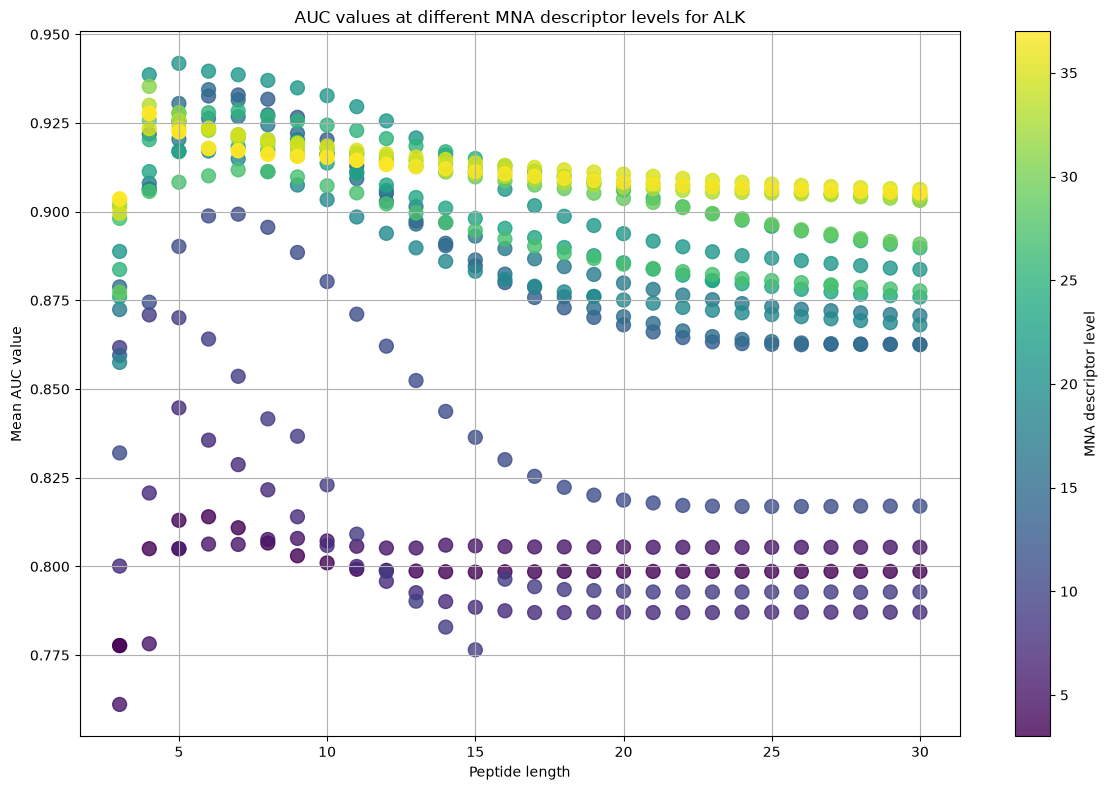

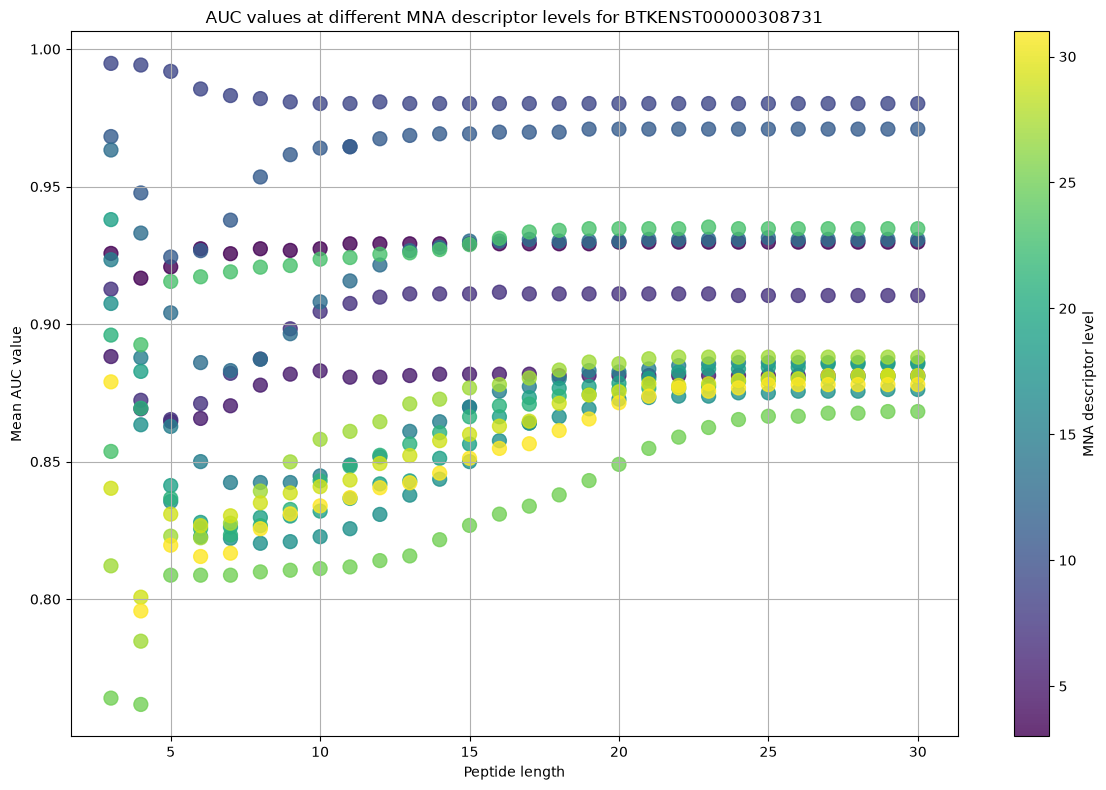

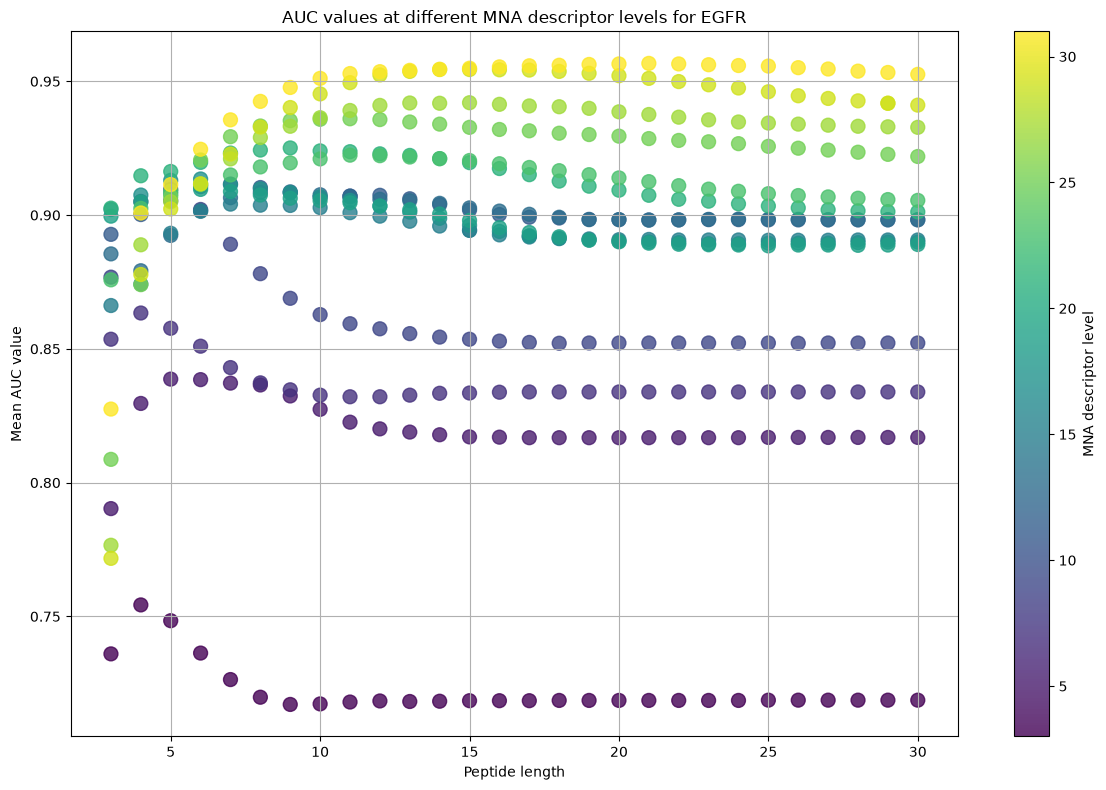

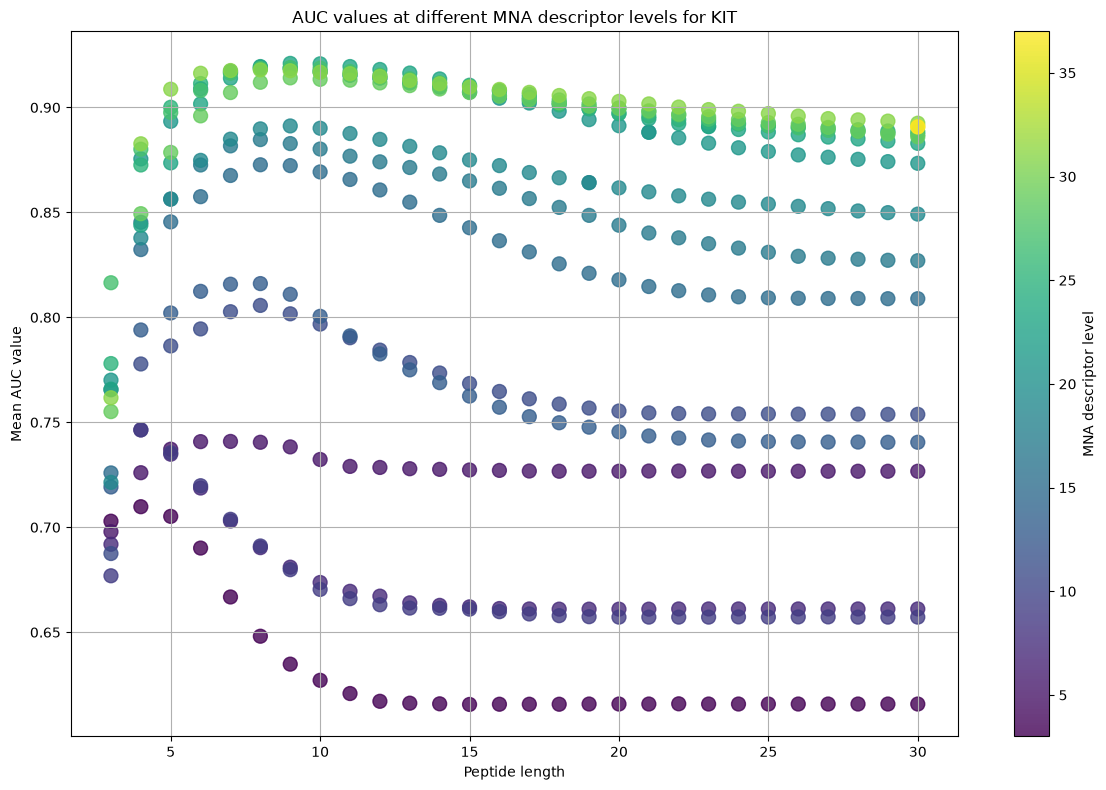

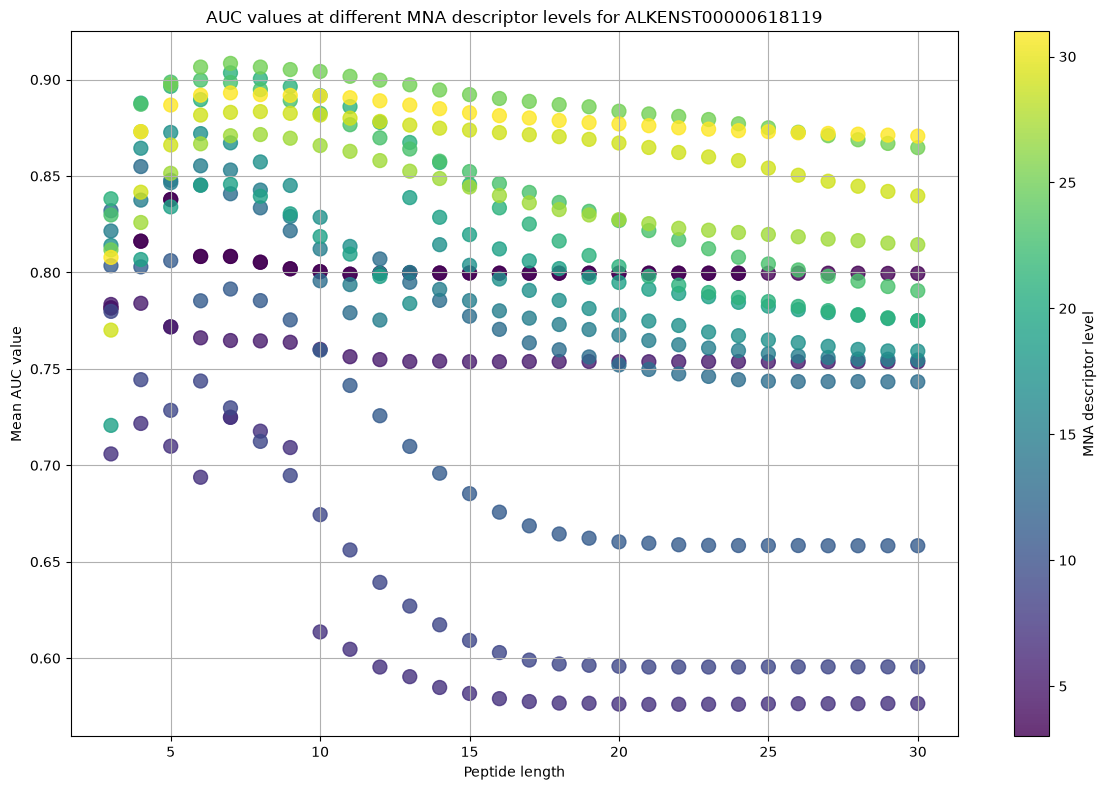

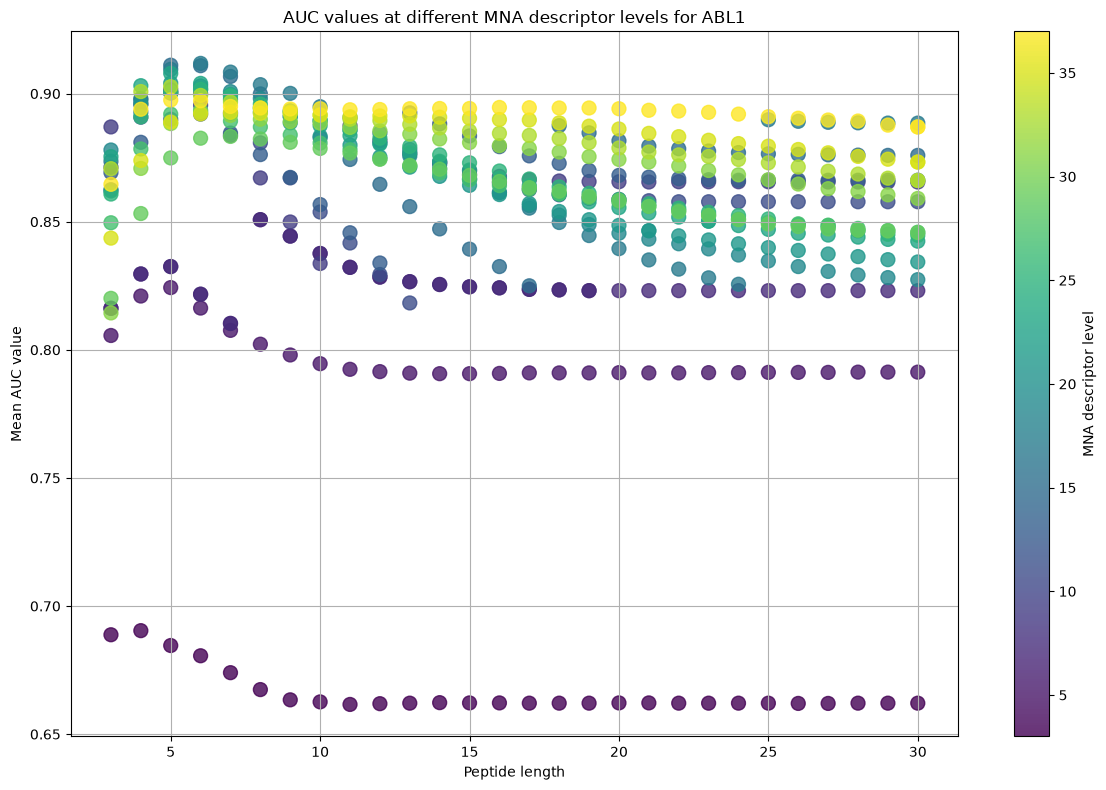

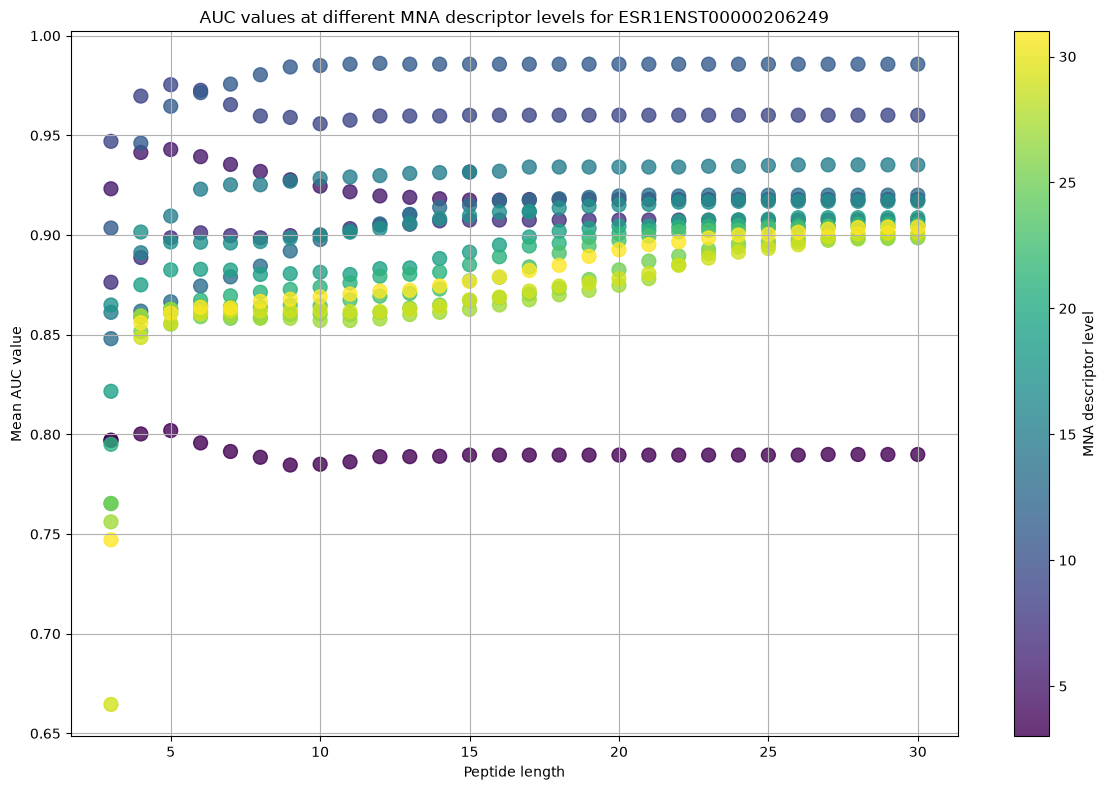

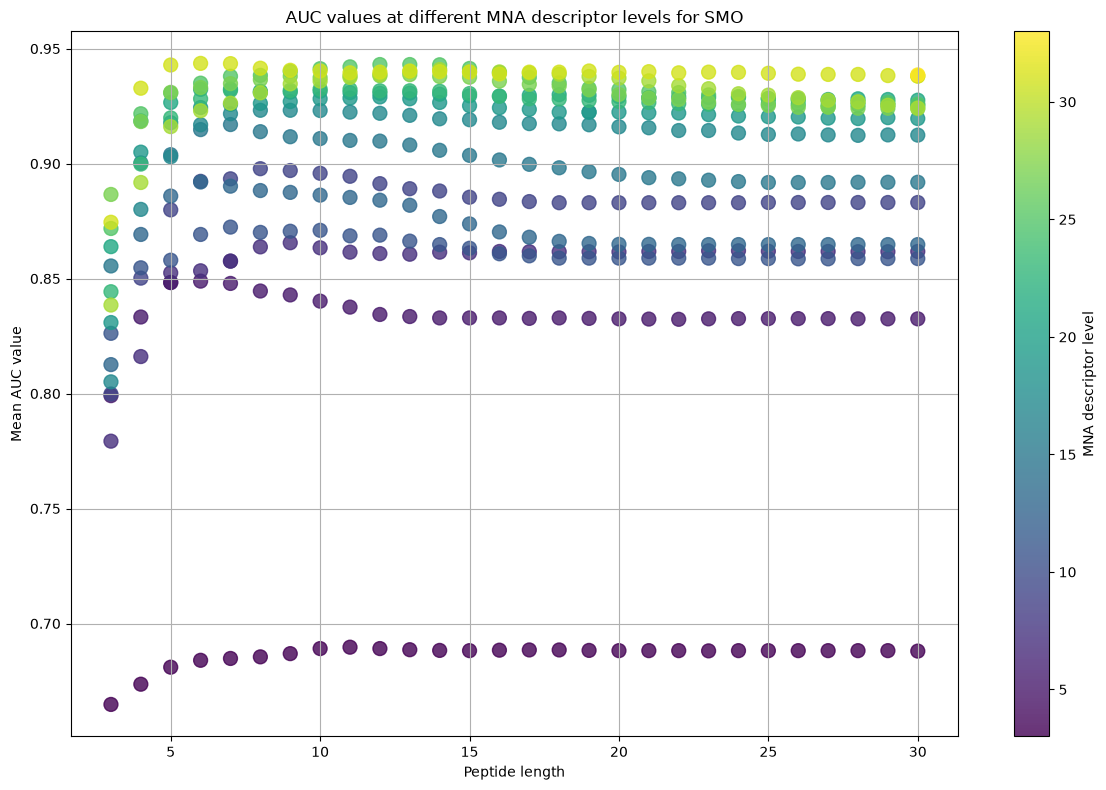

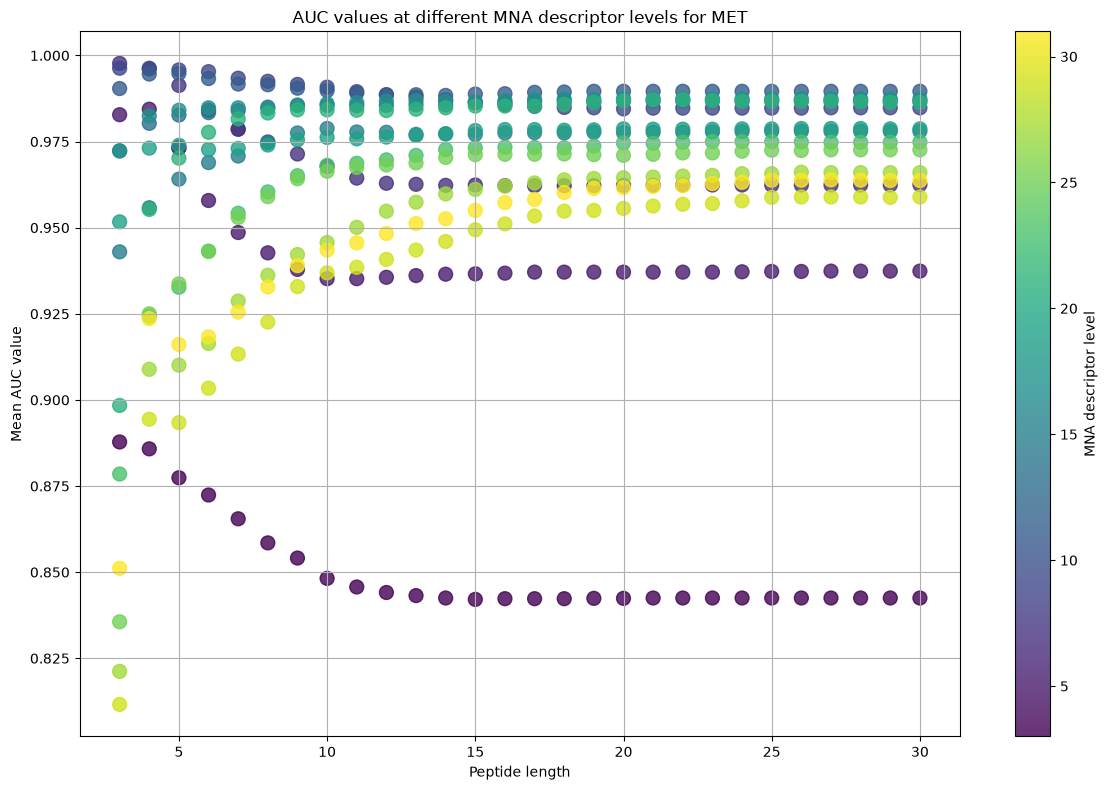

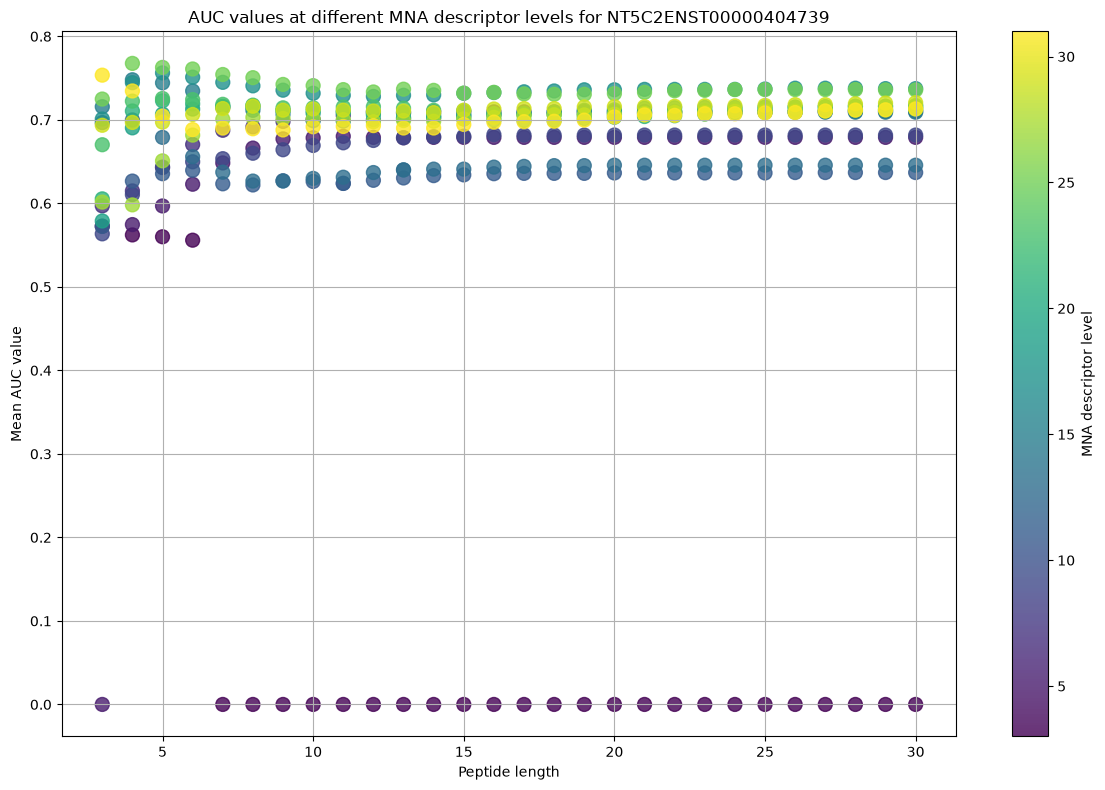

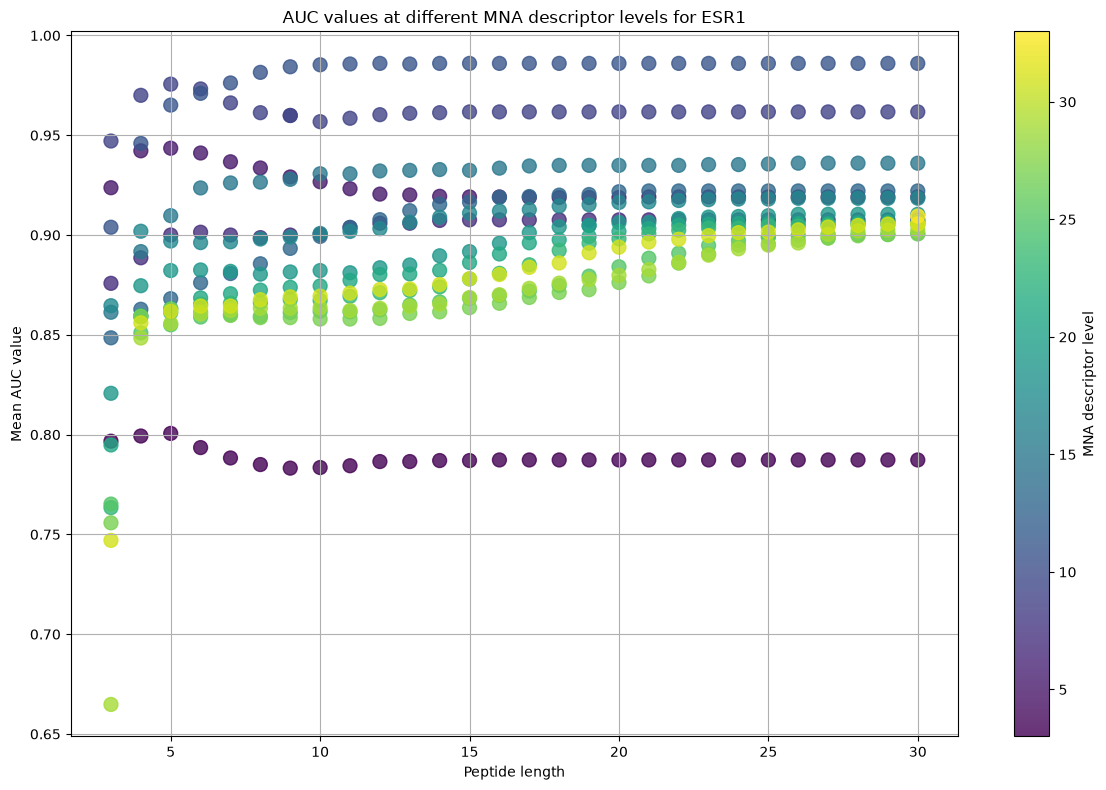

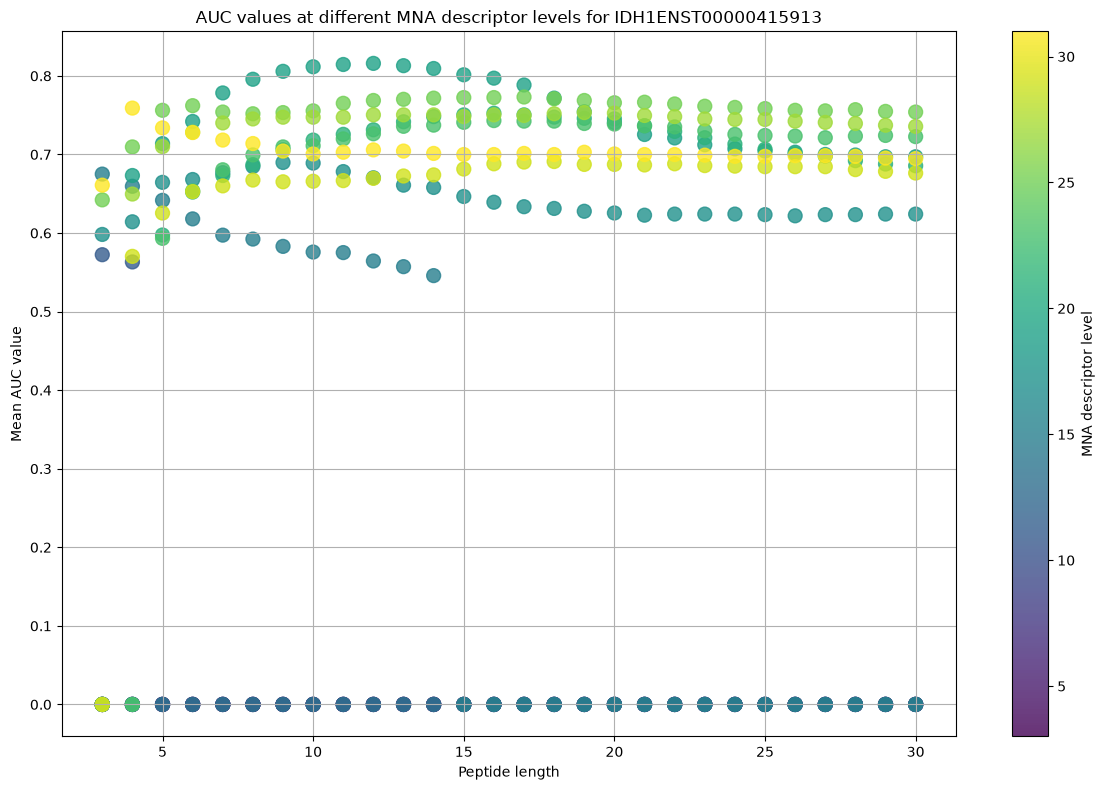

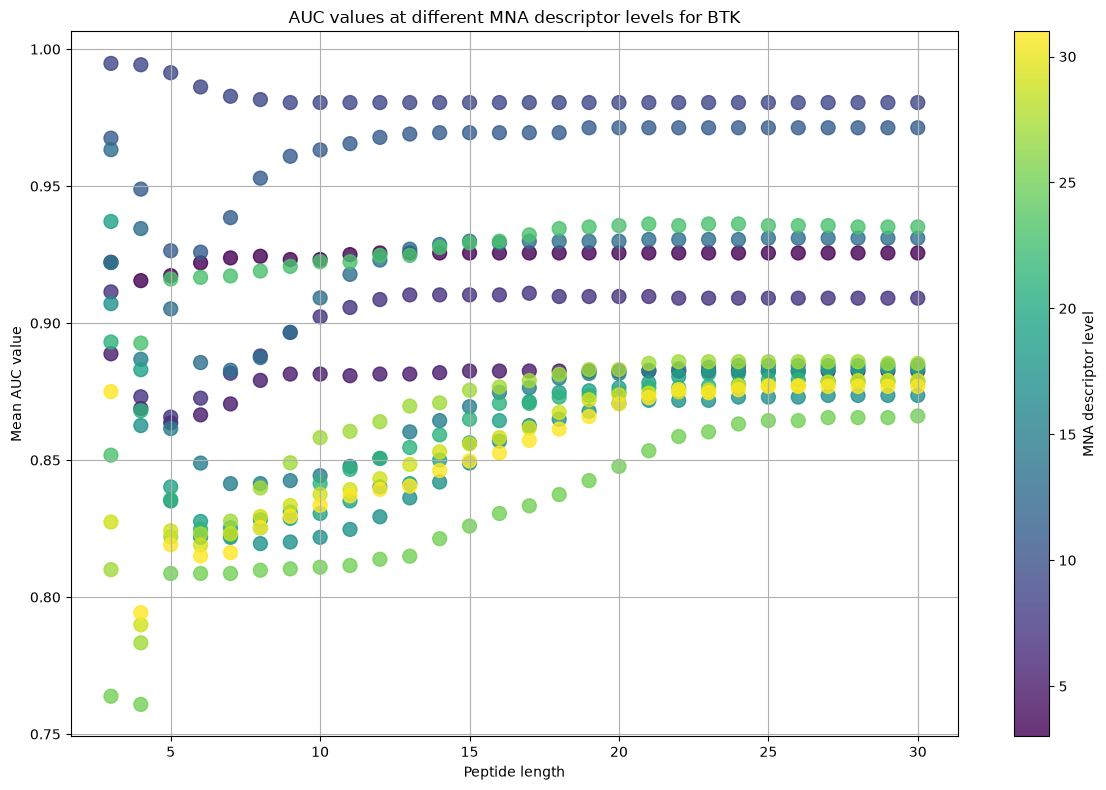

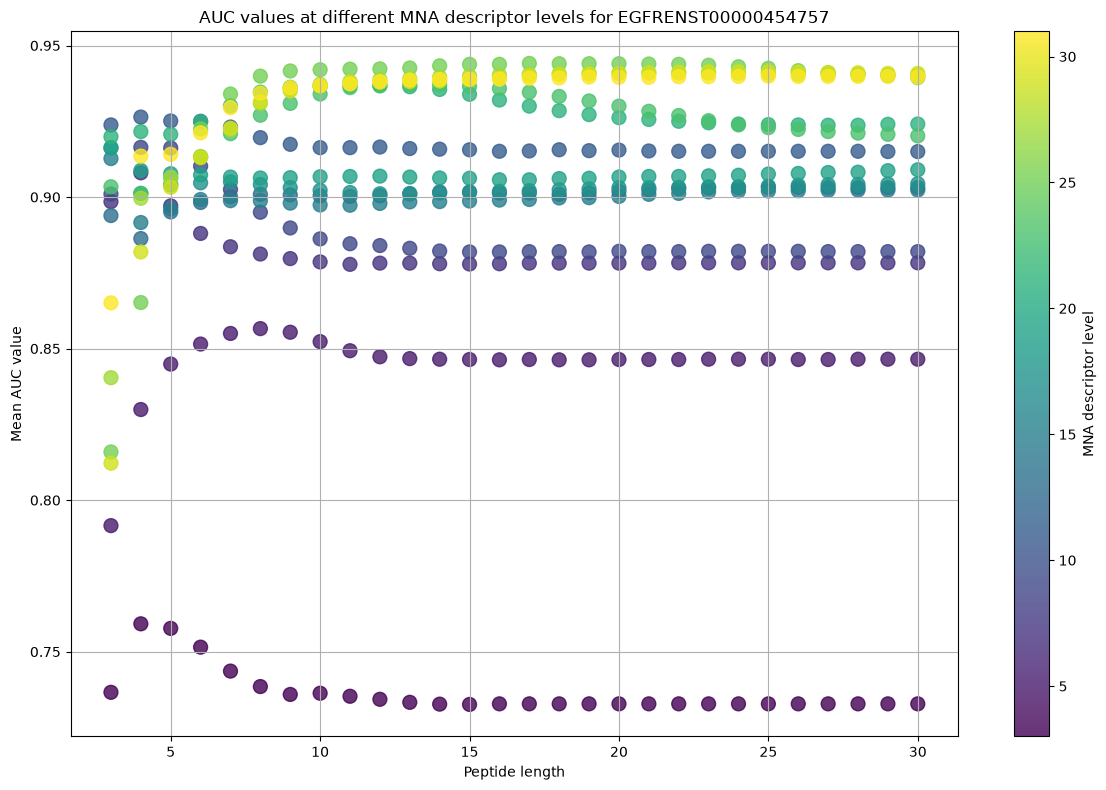

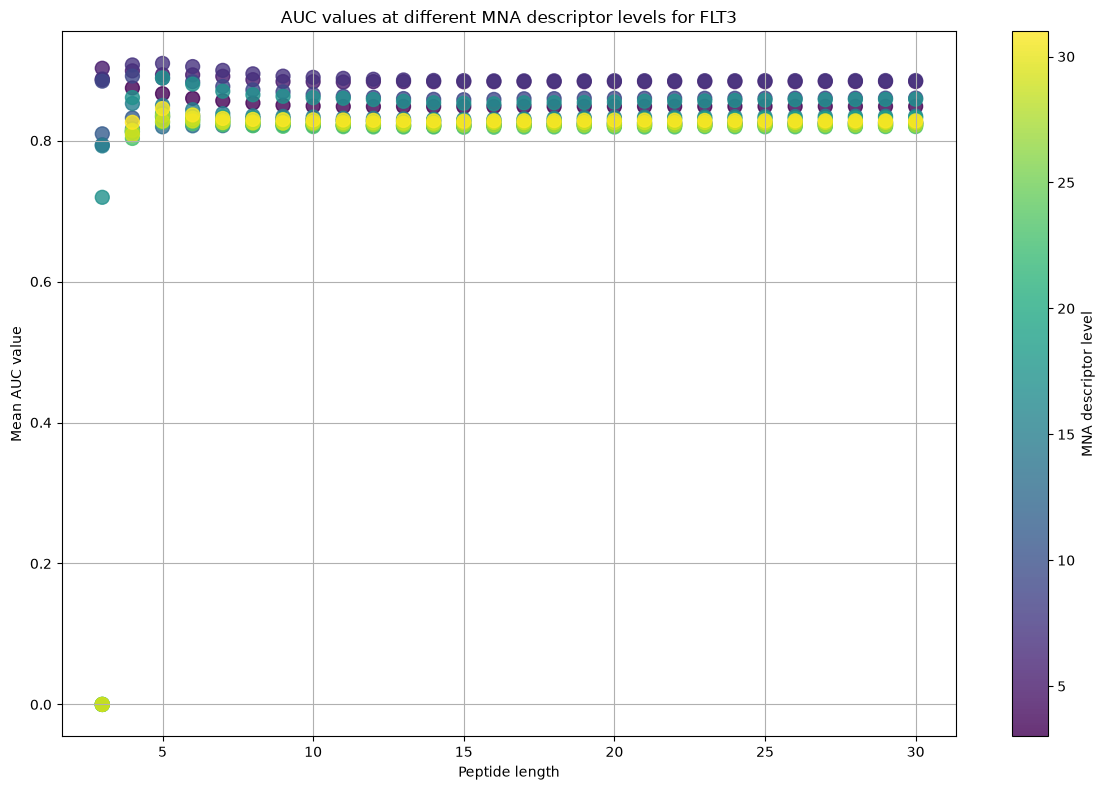

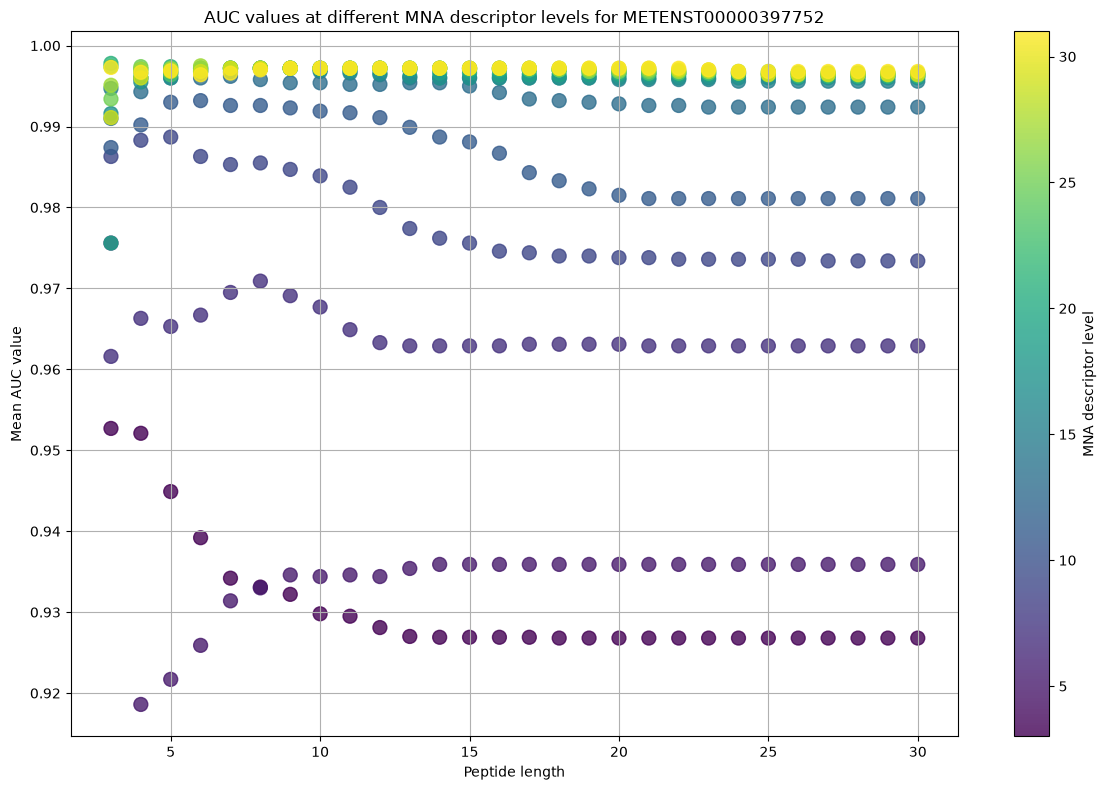

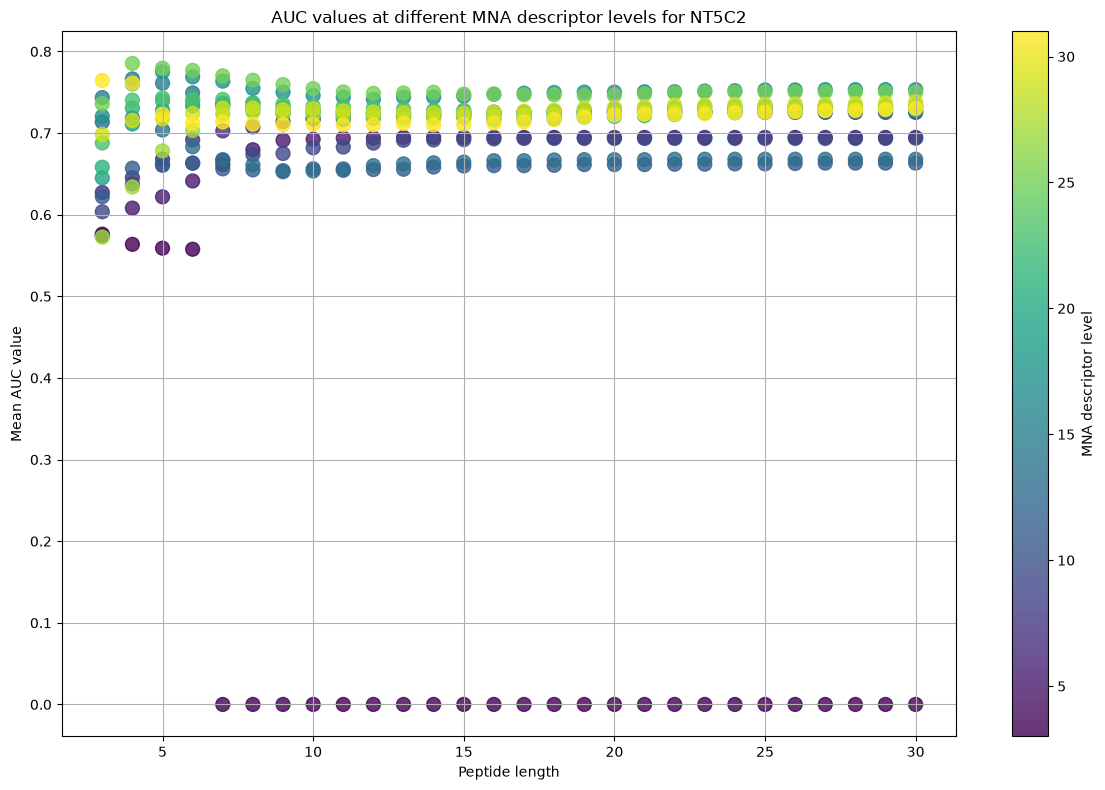

In [24]:
import os
import re
import matplotlib.pyplot as plt

# Function to parse the merged file with multiple proteins
def parse_file(file_path):
    results = {}
    current_gene = None
    current_protein = None
    current_mna = None
    current_sdf = None
    current_iap = None
    current_peptide_length = None

    with open(file_path, 'r', encoding='utf-8') as file:
        for line in file:
            line = line.strip()

            # Extract full gene name and peptide length (handling all types of SDF names)
            gene_match = re.search(r"Data from ([A-Za-z0-9_]+)_(\d+)\.sdf is added", line)
            if gene_match:
                full_gene = gene_match.group(1)  # Full identifier (e.g., "BTK_ENST00000308731")
                current_peptide_length = int(gene_match.group(2))  # Peptide length (e.g., "29")

                # Normalize the gene name by removing underscores between the protein and gene part
                normalized_gene = full_gene.replace("_", "")  # Remove underscores

                # Extract the protein name: everything before the last underscore
                current_protein = normalized_gene  # The entire normalized gene name is the protein name

                if normalized_gene not in results:
                    results[normalized_gene] = []  # Create a list for this gene

                current_gene = normalized_gene  # Assign the normalized gene identifier for storage

            # Extract MNA level
            mna_match = re.search(r"MNA-(\d+)", line)
            if mna_match:
                current_mna = int(mna_match.group(1))

            # Extract IAP value
            iap_match = re.search(r"Average IAP:\s+([0-9\.]+)", line)
            if iap_match:
                current_iap = float(iap_match.group(1))

            # Store the result when all components are found
            if current_gene and current_mna and current_peptide_length is not None and current_iap is not None:
                results[current_gene].append({
                    "Protein": current_protein,
                    "MNA": current_mna,
                    "SDF": current_gene + ".sdf",
                    "IAP": current_iap,
                    "Peptide_Length": current_peptide_length
                })
                # Reset values for the next entry
                current_mna = None
                current_gene = None
                current_protein = None
                current_peptide_length = None
                current_iap = None

    return results

# Path to the merged file
merged_file_path = str(DATA_DIR / "multipass results" / "merged.txt")

# Parse the merged file
parsed_results = parse_file(merged_file_path)

# 📊 Plot data for each gene (full identifier)
for gene, data in parsed_results.items():
    if not data:
        continue  # Skip empty entries

    # Sort data by MNA level and peptide length
    data.sort(key=lambda x: (x["MNA"], x["Peptide_Length"]))

    # Prepare data for plotting
    mna_levels = [item["MNA"] for item in data]
    iap_values = [item["IAP"] for item in data]
    peptide_lengths = [item["Peptide_Length"] for item in data]

    # Normalize peptide lengths for color mapping
    colors = [length for length in peptide_lengths]

    # Plot the data
    plt.figure(figsize=(12, 8))
    sc = plt.scatter(mna_levels, iap_values, c=colors, cmap='viridis', s=100, alpha=0.8)
    plt.colorbar(sc, label="MNA descriptor level")

    plt.title(f"AUC values at different MNA descriptor levels for {gene}")
    plt.xlabel("Peptide length")
    plt.ylabel("Mean AUC value")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

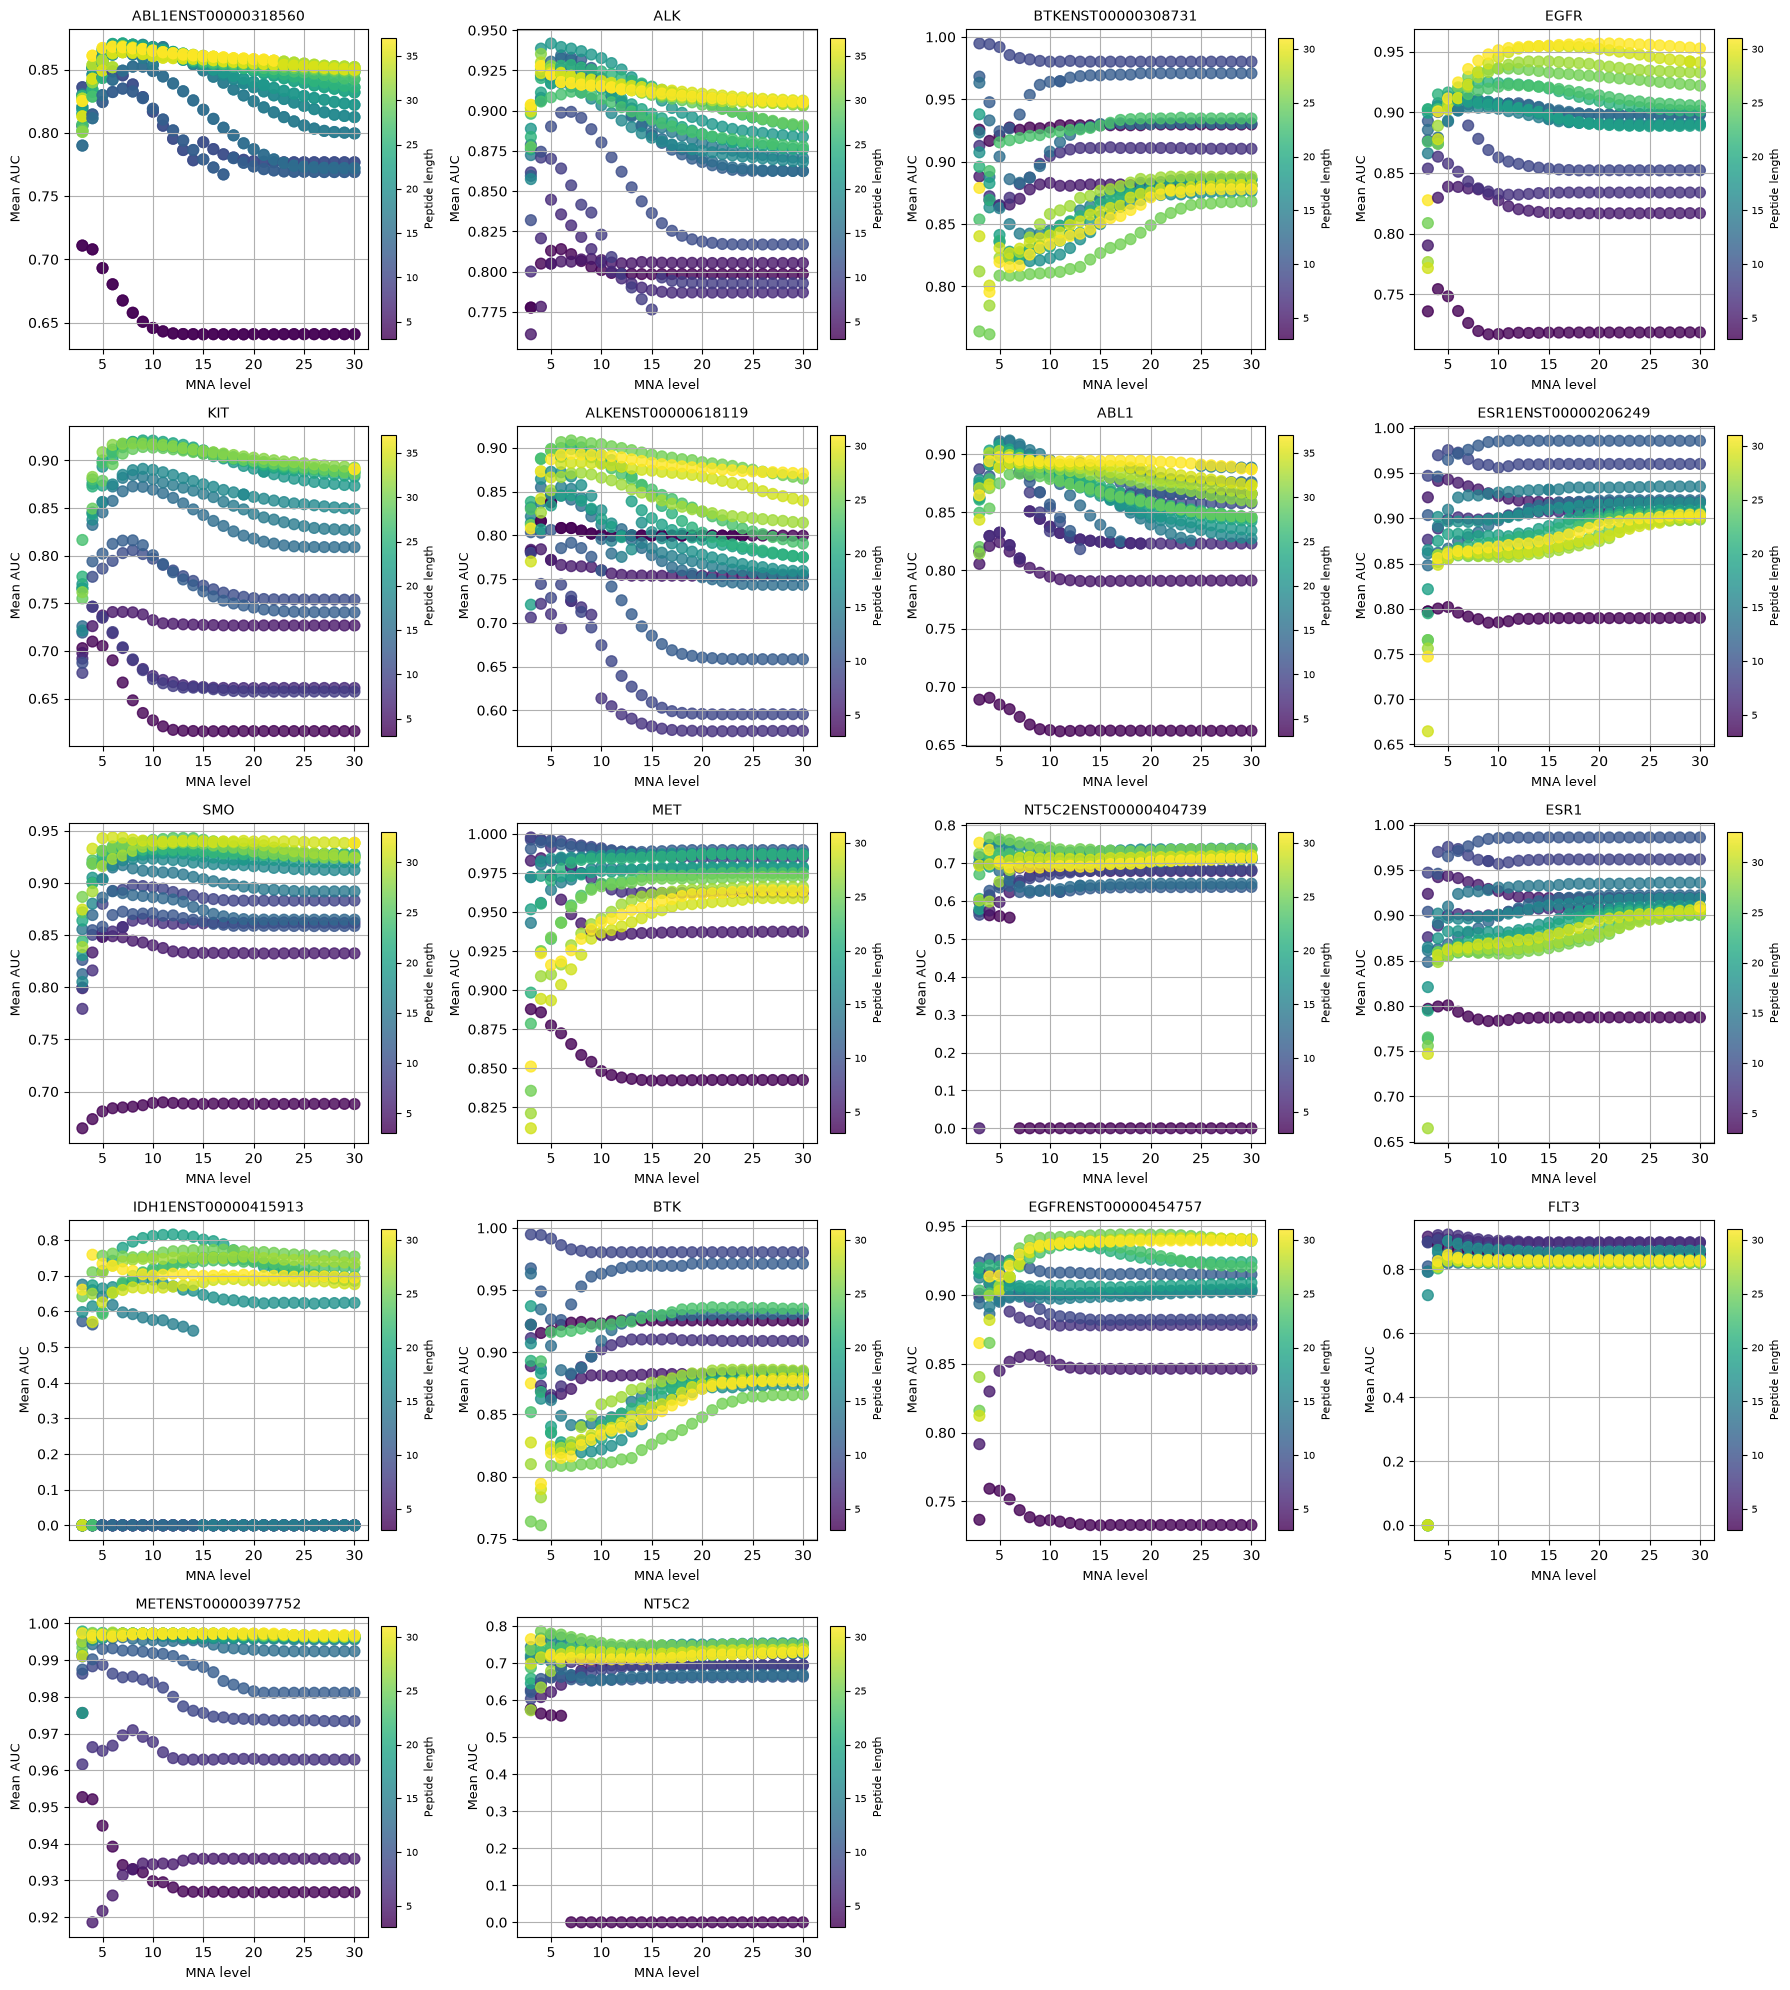

In [25]:
import math

genes = list(parsed_results.keys())
n_genes = len(genes)

n_cols = 4
n_rows = math.ceil(n_genes / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5*n_cols, 4*n_rows))
axes = axes.flatten()

for ax, gene in zip(axes, genes):
    data = parsed_results[gene]
    if not data:
        ax.axis("off")
        continue

    data.sort(key=lambda x: (x["MNA"], x["Peptide_Length"]))

    mna_levels = [item["MNA"] for item in data]
    iap_values = [item["IAP"] for item in data]
    peptide_lengths = [item["Peptide_Length"] for item in data]

    sc = ax.scatter(
        mna_levels,
        iap_values,
        c=peptide_lengths,
        cmap='viridis',
        s=60,
        alpha=0.8
    )

    ax.set_title(gene, fontsize=10)
    ax.set_xlabel("MNA level", fontsize=9)
    ax.set_ylabel("Mean AUC", fontsize=9)
    ax.grid(True)

    # One colour bar per panel: AUC ranges differ a lot between targets
    cbar = plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Peptide length", fontsize=8)
    cbar.ax.tick_params(labelsize=7)

# Blank out the unused panels in the last row
for ax in axes[n_genes:]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/iap_mna_peptide_scatter.png")
plt.show()


In [27]:
from collections import defaultdict

# Step 1: Group IAP values by (Peptide Length, MNA Level) for each protein
protein_best_iap = defaultdict(lambda: {"Max_IAP": -float('inf'), "Best_Combination": None})

for protein, data in parsed_results.items():
    for result in data:
        iap = result["IAP"]
        key = (result["Peptide_Length"], result["MNA"])

        # Update the best combination if a higher IAP is found
        if iap > protein_best_iap[protein]["Max_IAP"]:
            protein_best_iap[protein]["Max_IAP"] = iap
            protein_best_iap[protein]["Best_Combination"] = key

# Step 2: Print results
print("🔥 Best IAP for each protein:")
for protein, info in protein_best_iap.items():
    length, mna = info["Best_Combination"]
    print(f"Protein: {protein}, Peptide Length: {length}, MNA Level: {mna}, Max IAP: {info['Max_IAP']}")

🔥 Best IAP for each protein:
Protein: ABL1ENST00000318560, Peptide Length: 23, MNA Level: 7, Max IAP: 0.8706
Protein: ALK, Peptide Length: 21, MNA Level: 5, Max IAP: 0.9418
Protein: BTKENST00000308731, Peptide Length: 9, MNA Level: 3, Max IAP: 0.9948
Protein: EGFR, Peptide Length: 31, MNA Level: 21, Max IAP: 0.9567
Protein: KIT, Peptide Length: 23, MNA Level: 9, Max IAP: 0.921
Protein: ALKENST00000618119, Peptide Length: 25, MNA Level: 7, Max IAP: 0.9084
Protein: ABL1, Peptide Length: 17, MNA Level: 6, Max IAP: 0.9118
Protein: ESR1ENST00000206249, Peptide Length: 11, MNA Level: 12, Max IAP: 0.9861
Protein: SMO, Peptide Length: 31, MNA Level: 6, Max IAP: 0.9436
Protein: MET, Peptide Length: 7, MNA Level: 3, Max IAP: 0.9977
Protein: NT5C2ENST00000404739, Peptide Length: 25, MNA Level: 4, Max IAP: 0.7676
Protein: ESR1, Peptide Length: 11, MNA Level: 12, Max IAP: 0.986
Protein: IDH1ENST00000415913, Peptide Length: 19, MNA Level: 12, Max IAP: 0.8159
Protein: BTK, Peptide Length: 9, MNA Leve

## 9. Final model summary

The best model per target and drug, transcribed from
`results/final table web.xlsx`. `IAP_LOO` is leave-one-out cross-validated AUC,
`IAP_20fold` is 20-fold; `N` is the number of mutations the model was trained
on, and `Charge` says whether formal charges were assigned to the peptides.

Inlined as text rather than read from the spreadsheet so the figure below
reproduces without the data folder.

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

import pandas as pd
from io import StringIO

raw_data = """
Protein_target\tN\tPeptide_length\tMNA_level\tIAP_LOO\tIAP_20fold\tDrug\tCharge
ABL1\t30\t33\t5\t0.934\t0.929\tImatinib\tNo
ABL1\t9\t11\t5\t0.890\t0.873\tTyrosine kinase inhibitor\tYes
ABL1ENST00000318560\t9\t17\t9\t0.869\t0.871\tNilotinib\tNo
ABL1ENST00000318560\t87\t17\t9\t0.894\t0.889\tImatinib\tNo
ABL1ENST00000318560\t48\t17\t9\t0.871\t0.844\tTyrosine kinase inhibitor\tNo
ABL1ENST00000318560\t5\t17\t7\t0.839\t0.782\tBosutinib\tNo
ABL1ENST00000318560\t10\t11\t6\t0.915\t0.914\tDasatinib\tNo
ALK\t5\t21\t5\t0.988\t0.988\tAlectinib\tNo
ALK\t7\t15\t5\t0.909\t0.983\tLorlatinib\tNo
ALK\t16\t33\t4\t0.947\t0.940\tCrizotinib\tNo
ALK\t8\t11\t6\t0.926\t0.925\tCeritinib\tYes
ALK\t4\t35\t3\t0.992\t0.988\tBrigatinib\tNo
ALKENST00000618119\t9\t21\t4\t0.869\t0.864\tCrizotinib\tNo
ALKENST00000618119\t4\t25\t7\t0.913\t0.979\tAlectinib\tNo
ALKENST00000618119\t3\t13\t4\t0.931\t0.936\tLorlatinib\tNo
BTK\t5\t9\t3\t0.995\t0.995\tIbrutinib\tNo
BTKENST00000308731\t5\t9\t3\t0.995\t0.995\tIbrutinib\tNo
EGFR\t16\t37\t30\t0.966\t0.965\tOsimertinib\tNo
EGFRENST00000454757\t13\t11\t19\t0.941\t0.941\tOsimertinib\tYes
ESR1\t7\t11\t27\t0.986\t0.986\tEndocrine therapy\tNo
ESR1ENST00000206249\t7\t11\t12\t0.986\t0.986\tEndocrine therapy\tNo
FLT3\t5\t7\t5\t0.923\t0.926\tQuizartinib\tNo
FLT3\t4\t7\t5\t0.881\t0.884\tSorafenib\tNo
IDH1ENST00000415913\t6\t19\t12\t0.816\t0.816\tIvosidenib\tNo
KIT\t23\t23\t9\t0.920\t0.919\tImatinib\tNo
MET\t7\t7\t3\t0.997\t0.997\tCrizotinib\tYes
METENST00000397752\t3\t21\t3\t0.997\t0.997\tCrizotinib\tYes
NT5C2\t18\t25\t4\t0.786\t0.784\tPurine\tYes
NT5C2ENST00000404739\t17\t25\t4\t0.768\t0.781\tPurine\tYes
SMO\t18\t31\t7\t0.944\t0.897\tVismodegib\tNo
"""

df = pd.read_csv(StringIO(raw_data), sep="\t")

df = pd.DataFrame(df, columns=[
    "Protein_target","N","Peptide_length","MNA_level",
    "IAP_LOO","IAP_20fold","Drug","Charge"
])



In [35]:
df

,Protein_target,N,Peptide_length,MNA_level,IAP_LOO,IAP_20fold,Drug,Charge
0,ABL1,30,33,5,0.934,0.929,Imatinib,No
1,ABL1,9,11,5,0.890,0.873,Tyrosine kinase inhibitor,Yes
2,ABL1ENST00000318560,9,17,9,0.869,0.871,Nilotinib,No
3,ABL1ENST00000318560,87,17,9,0.894,0.889,Imatinib,No
4,ABL1ENST00000318560,48,17,9,0.871,0.844,Tyrosine kinase inhibitor,No
5,ABL1ENST00000318560,5,17,7,0.839,0.782,Bosutinib,No
6,ABL1ENST00000318560,10,11,6,0.915,0.914,Dasatinib,No
7,ALK,5,21,5,0.988,0.988,Alectinib,No
8,ALK,7,15,5,0.909,0.983,Lorlatinib,No
9,ALK,16,33,4,0.947,0.940,Crizotinib,No


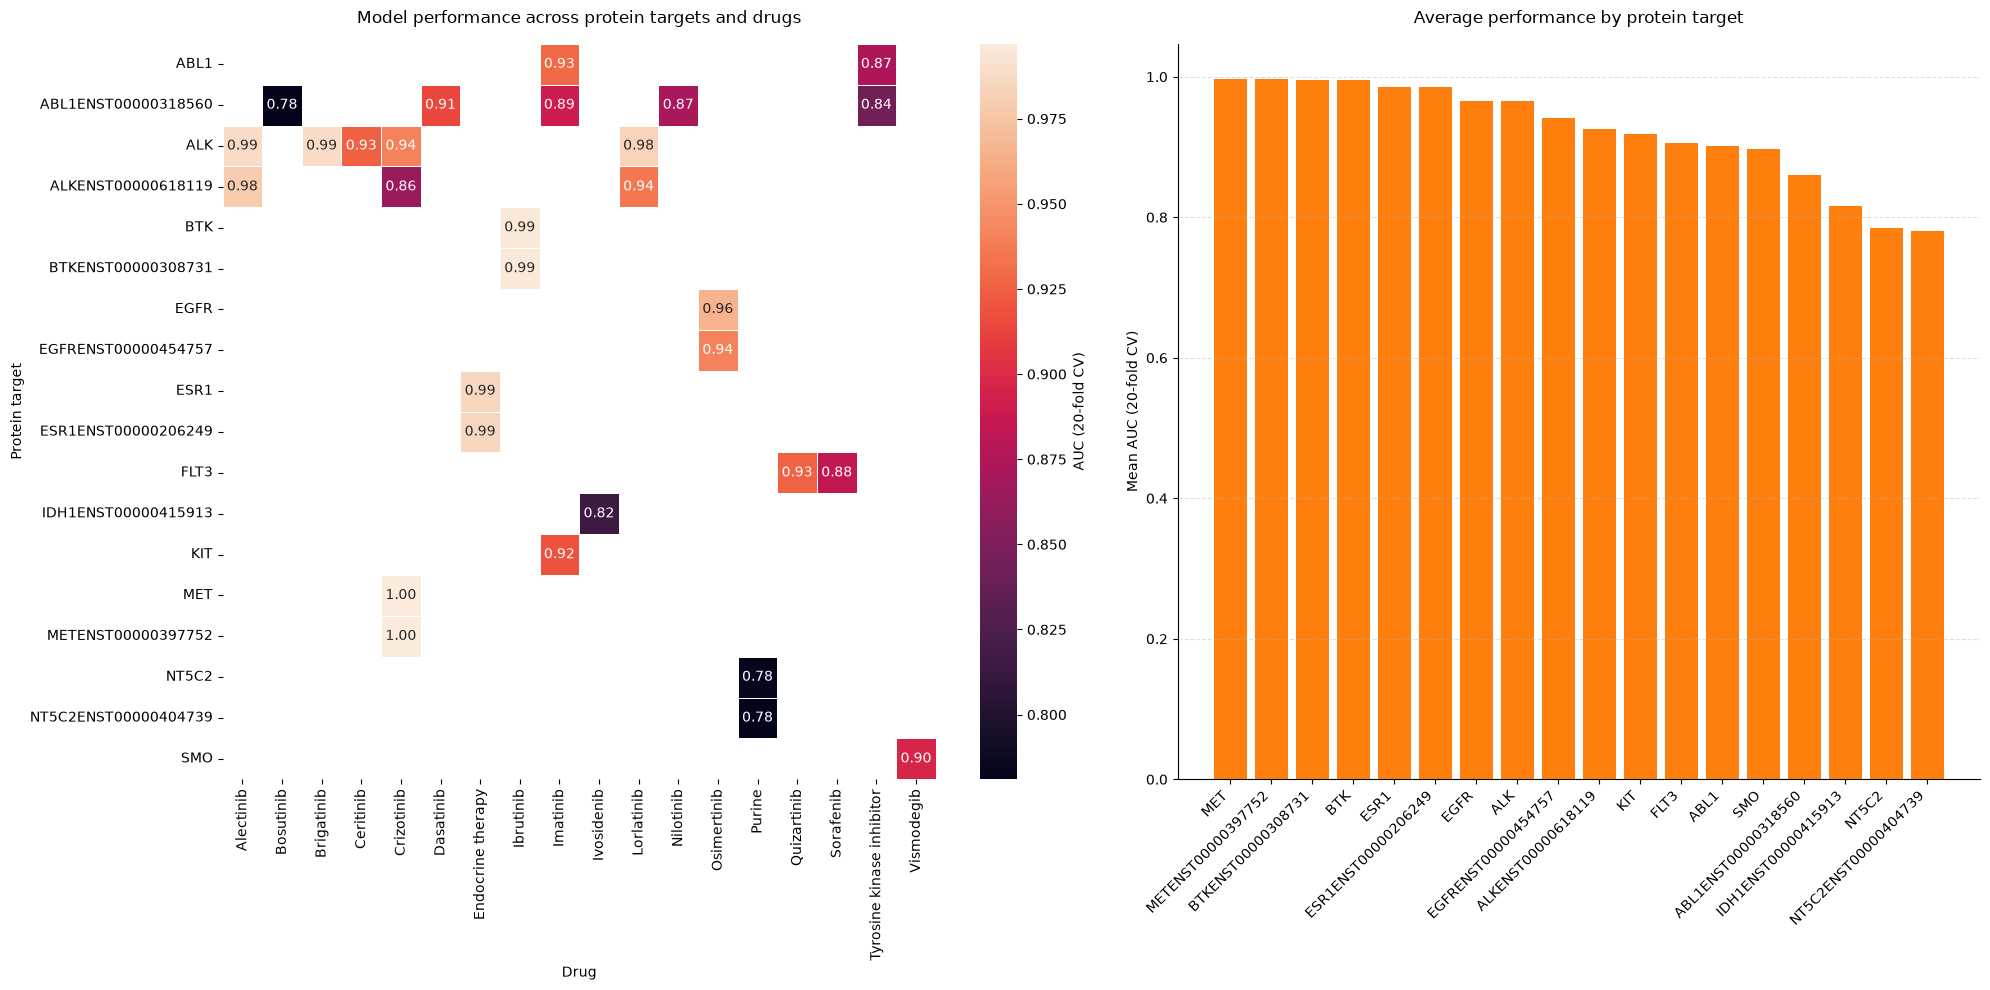

In [39]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- data ---
df_clean = df.copy()

pivot = df_clean.pivot_table(
    index="Protein_target",
    columns="Drug",
    values="IAP_20fold",
    aggfunc="mean"
)

# Bar order is independent of the heatmap: targets sorted by mean AUC
means = df_clean.groupby("Protein_target")["IAP_20fold"].mean().sort_values(ascending=False)

# --- plot ---
fig, axes = plt.subplots(
    ncols=2,
    figsize=(20, 10),
    gridspec_kw={"width_ratios": [10, 9]}
)

# --- heatmap ---
sns.heatmap(
    pivot,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "AUC (20-fold CV)"},
    ax=axes[0]
)

axes[0].set_title("Model performance across protein targets and drugs", pad=15)
axes[0].set_xlabel("Drug")
axes[0].set_ylabel("Protein target")

# --- bar chart: mean AUC per target ---
axes[1].bar(
    range(len(means)),
    means.values
)
axes[1].bar(range(len(means)), means.values)

axes[1].set_xticks(range(len(means)))
axes[1].set_xticklabels(means.index, rotation=45, ha='right')

axes[1].set_ylabel("Mean AUC (20-fold CV)")
axes[1].set_title("Average performance by protein target", pad=15)

axes[1].grid(axis='y', linestyle='--', alpha=0.4)


axes[1].grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/Figure2_clean.png", dpi=600)
plt.show()

---

**Open question.** Model selection is still done by hand: the table above was
assembled from `results/final table web.xlsx`, which records the winning
peptide length / MNA level / charge per target and drug. Worth automating —
the inputs are all in `parsed_results` and the `.HST` reports.